# Practical 10 — Cheminformatics and QSAR

## hERG / KCNH2 activity from ChEMBL

### Main question

**How does the choice of molecular representation affect prediction of hERG activity?**

We will compare:

1. small interpretable molecular descriptors,
2. a larger RDKit descriptor space,
3. Morgan / ECFP fingerprints,
4. a graph neural network,
5. optionally 3D and dynamic descriptors.

The same cleaned molecular dataset and the same train/validation/test partitions should be reused across model families.

### Learning objectives

By the end of this practical, students should be able to:
- retrieve molecular bioactivity data from ChEMBL;
- clean and standardize structure–activity data;
- calculate molecular descriptors from first principles and with RDKit;
- generate Morgan fingerprints and calculate Tanimoto similarity;
- build QSAR regression models;
- create scaffold-aware train/test splits;
- define a simple applicability domain;
- represent molecules as graphs for a GNN;
- compare hand-crafted and learned molecular representations.

## How to use this notebook

This practical is intentionally written as a sequence of small experiments. Run the cells from top to bottom and inspect the object created by each step before moving on.

The central question is:

> How does the molecular representation and the validation split affect hERG activity prediction?

We will use the same cleaned molecules for every model family. This makes the comparison meaningful: when a score changes, we can attribute the change mainly to the representation, model, or split.

**Important:** ChEMBL retrieval and 3D/GNN sections can be slow. The retrieval cells cache their results locally. The PyL3DMD descriptors were calculated once for a 150-molecule subset and saved as a reusable matrix; the main notebook loads that matrix instead of rerunning the expensive calculation.


# 0. Imports and reproducibility

We first import the libraries used throughout the practical and fix random seeds. Reproducibility does not guarantee identical results on every computer, but it makes accidental changes easier to detect.


In [103]:
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.MolStandardize import rdMolStandardize

from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    XGBRegressor = None
    HAS_XGB = False
    warnings.warn("xgboost is not installed; XGBoost cells will be skipped.")


In [104]:
SEED = 111126
np.random.seed(SEED)
random.seed(SEED)


## 1. Retrieve hERG activity from ChEMBL

**ChEMBL is a relational bioactivity resource.** The important objects in this workflow are:

- a **target**: here, `CHEMBL240`, the hERG/KCNH2 potassium channel;
- an **activity record**: one measured compound–target result, linked to a molecule and an assay;
- a **molecule**: a compound identified by a stable ChEMBL ID and described by a structure such as SMILES;
- an **assay**: the experimental context in which the measurement was obtained.

The activity endpoint is retrieved in two stages. First, we query activity records for the target and request the normalized `IC50` endpoint. Second, we query the molecule records for the IDs returned by the first query and join their canonical SMILES to the activity table. Thus, the raw table is initially an **assay-level observation table**, not yet a one-row-per-molecule machine-learning table.

The API fields beginning with `standard_` are ChEMBL's standardized representation of the reported measurement. We keep the assay ID, assay type, relation symbol, confidence score, and original molecule ID because they help us audit heterogeneity before aggregation.


In [105]:
TARGET_ID = "CHEMBL240"
MAX_ACTIVITY_ROWS = 5000
RAW_ACTIVITY_PATH = Path("chembl_herg_ic50_raw.csv")

print("Target:", TARGET_ID)
print("Activity cache:", RAW_ACTIVITY_PATH)


Target: CHEMBL240
Activity cache: chembl_herg_ic50_raw.csv


### 1.1 Download or load the activity table

The query below is deliberately narrow: `target_chembl_id=CHEMBL240` selects hERG, and `standard_type="IC50"` selects the concentration that produces 50% inhibition under a particular assay definition. The `.only(...)` call requests only the columns needed for auditing and modeling. ChEMBL returns a sequence of records; `pd.DataFrame` turns those records into a table, and the CSV cache makes later notebook runs deterministic and avoids repeated API requests.

The API may return several activity records for one molecule because the compound was tested in multiple assays, laboratories, or experimental conditions. We therefore inspect and clean the records before taking a molecule-level summary.


In [106]:
if RAW_ACTIVITY_PATH.exists():
    activities = pd.read_csv(RAW_ACTIVITY_PATH)
    print(f"Loaded cached activity table: {RAW_ACTIVITY_PATH}")
else:
    from chembl_webresource_client.new_client import new_client

    activity = new_client.activity
    query = activity.filter(
        target_chembl_id=TARGET_ID,
        standard_type="IC50",
    ).only(
        "molecule_chembl_id", "standard_value", "standard_units",
        "standard_relation", "assay_chembl_id", "assay_type",
        "target_chembl_id", "pchembl_value", "confidence_score",
    )
    activities = pd.DataFrame(list(query[:MAX_ACTIVITY_ROWS]))
    activities.to_csv(RAW_ACTIVITY_PATH, index=False)
    print(f"Retrieved and cached {len(activities):,} activity rows.")


Loaded cached activity table: chembl_herg_ic50_raw.csv


**What one row means.** At this point one row is one ChEMBL activity observation. The same compound can occur many times, so do not interpret the row count as the number of unique molecules.


In [107]:
print("Activity query provenance:")
print({
    "target_chembl_id": TARGET_ID,
    "standard_type": "IC50",
    "requested_fields": [
        "molecule_chembl_id", "standard_value", "standard_units",
        "standard_relation", "assay_chembl_id", "assay_type",
        "target_chembl_id", "pchembl_value", "confidence_score",
    ],
    "row_interpretation": "one activity observation, not one unique molecule",
})
print("Activity rows:", len(activities))
print("Unique molecules:", activities["molecule_chembl_id"].nunique())
print("Unique assays:", activities["assay_chembl_id"].nunique())


Activity query provenance:
{'target_chembl_id': 'CHEMBL240', 'standard_type': 'IC50', 'requested_fields': ['molecule_chembl_id', 'standard_value', 'standard_units', 'standard_relation', 'assay_chembl_id', 'assay_type', 'target_chembl_id', 'pchembl_value', 'confidence_score'], 'row_interpretation': 'one activity observation, not one unique molecule'}
Activity rows: 5000
Unique molecules: 4127
Unique assays: 452


### 1.2 Inspect the raw activity table

Before cleaning, check the table shape, columns, units, and relation symbols. This is a general data-preparation habit: understand what was measured before transforming it.


In [108]:
print("shape:", activities.shape)
display(activities.head())
display(activities.dtypes.rename("dtype").to_frame())


shape: (5000, 12)


,assay_chembl_id,assay_type,molecule_chembl_id,pchembl_value,relation,standard_relation,standard_units,standard_value,target_chembl_id,type,units,value
0,CHEMBL841079,T,CHEMBL12713,7.85,=,=,nM,14.0,CHEMBL240,IC50,nM,14.0
1,CHEMBL841078,F,CHEMBL12713,NaN,~,~,nM,3.0,CHEMBL240,IC50,nM,3.0
2,CHEMBL691014,F,CHEMBL1108,7.49,=,=,nM,32.2,CHEMBL240,IC50,nM,32.2
3,CHEMBL691013,F,CHEMBL2368925,5.22,=,=,nM,5950.0,CHEMBL240,IC50,nM,5950.0
4,CHEMBL691014,F,CHEMBL6966,6.84,=,=,nM,143.0,CHEMBL240,IC50,nM,143.0


,dtype
assay_chembl_id,object
assay_type,object
molecule_chembl_id,object
pchembl_value,float64
relation,object
standard_relation,object
standard_units,object
standard_value,float64
target_chembl_id,object
type,object


In [109]:
print("Units:")
display(activities["standard_units"].value_counts(dropna=False).head(10))

print("Relations:")
display(activities["standard_relation"].value_counts(dropna=False))


Units:


standard_units
nM     4158
NaN     839
ucm       3
Name: count, dtype: int64

Relations:


standard_relation
=      3467
NaN     840
>       636
<        50
>=        6
~         1
Name: count, dtype: int64

## 2. Retrieve molecular structures and display names

An activity record contains a molecule ID, but a model needs a structure. We use the IDs from the activity table to request molecular records from ChEMBL, extract canonical SMILES, and merge the result back on `molecule_chembl_id`.

We also request ChEMBL's preferred molecule name. Names are metadata for inspection and plots only; the model still uses the standardized structure. If a preferred name is absent or the lookup service is unavailable, the stable ChEMBL ID is used as a transparent fallback.


In [110]:
STRUCTURE_CACHE = Path("chembl_herg_structures.csv")
print("Structure cache:", STRUCTURE_CACHE)


Structure cache: chembl_herg_structures.csv


In [111]:
if STRUCTURE_CACHE.exists():
    structures = pd.read_csv(STRUCTURE_CACHE)
    print(f"Loaded cached structures: {STRUCTURE_CACHE}")
else:
    from chembl_webresource_client.new_client import new_client

    molecule = new_client.molecule
    unique_ids = activities["molecule_chembl_id"].dropna().astype(str).unique().tolist()
    records = []
    for position, chembl_id in enumerate(unique_ids, start=1):
        record = molecule.get(chembl_id)
        molecule_structures = record.get("molecule_structures") or {}
        records.append({
            "molecule_chembl_id": chembl_id,
            "canonical_smiles": molecule_structures.get("canonical_smiles"),
        })
        if position % 100 == 0:
            print(f"Retrieved {position}/{len(unique_ids)} structures")
    structures = pd.DataFrame(records)
    structures.to_csv(STRUCTURE_CACHE, index=False)


Loaded cached structures: chembl_herg_structures.csv


In [112]:
df = activities.merge(structures, on="molecule_chembl_id", how="left")

print("merged shape:", df.shape)
print("missing canonical SMILES:", int(df["canonical_smiles"].isna().sum()))
display(df[["molecule_chembl_id", "standard_value", "canonical_smiles"]].head())


merged shape: (5000, 13)
missing canonical SMILES: 25


,molecule_chembl_id,standard_value,canonical_smiles
0,CHEMBL12713,14.0,O=C1NCCN1CCN1CCC(c2cn(-c3ccc(F)cc3)c3ccc(Cl)cc...
1,CHEMBL12713,3.0,O=C1NCCN1CCN1CCC(c2cn(-c3ccc(F)cc3)c3ccc(Cl)cc...
2,CHEMBL1108,32.2,O=C(CCCN1CC=C(n2c(=O)[nH]c3ccccc32)CC1)c1ccc(F...
3,CHEMBL2368925,5950.0,O=C(O[C@@H]1C[C@@H]2C[C@H]3C[C@H](C1)N2CC3=O)c...
4,CHEMBL6966,143.0,COc1ccc(CCN(C)CCCC(C#N)(c2ccc(OC)c(OC)c2)C(C)C...


### 2.1 Resolve readable molecule names

ChEMBL IDs are reliable identifiers but are not convenient labels for a teaching plot. The preferred name is retrieved from the molecule record and cached locally. This lookup is intentionally kept separate from the activity query: the ID-to-name mapping is metadata and should never change the target or the molecular structure used by the model.


In [113]:
CHEMBL_NAME_CACHE = Path("chembl_molecule_names.csv")

if CHEMBL_NAME_CACHE.exists():
    molecule_names = pd.read_csv(CHEMBL_NAME_CACHE)
else:
    name_rows = []
    try:
        from chembl_webresource_client.new_client import new_client
        molecule_client = new_client.molecule
        molecule_ids = (
            df["molecule_chembl_id"]
            .dropna()
            .astype(str)
            .drop_duplicates()
            .tolist()
        )
        for position, molecule_id in enumerate(molecule_ids, start=1):
            try:
                record = molecule_client.get(molecule_id)
                preferred_name = record.get("pref_name")
            except Exception:
                preferred_name = None
            name_rows.append({
                "molecule_chembl_id": molecule_id,
                "molecule_name": preferred_name,
                "name_source": (
                    "ChEMBL preferred name"
                    if preferred_name else "ChEMBL ID fallback"
                ),
            })
            if position % 100 == 0:
                print(f"Resolved {position}/{len(molecule_ids)} molecule names")
    except Exception as exc:
        print("ChEMBL name lookup unavailable:", exc)

    molecule_names = pd.DataFrame(name_rows)
    if molecule_names.empty:
        molecule_names = df[["molecule_chembl_id"]].drop_duplicates().copy()
        molecule_names["molecule_name"] = molecule_names["molecule_chembl_id"]
        molecule_names["name_source"] = "ChEMBL ID fallback"
    molecule_names["molecule_name"] = molecule_names["molecule_name"].fillna(
        molecule_names["molecule_chembl_id"]
    )
    molecule_names.to_csv(CHEMBL_NAME_CACHE, index=False)

df = df.merge(
    molecule_names,
    on="molecule_chembl_id",
    how="left",
    validate="many_to_one",
)
df["molecule_name"] = df["molecule_name"].fillna(df["molecule_chembl_id"])
display(df[["molecule_chembl_id", "molecule_name", "canonical_smiles"]].head())


,molecule_chembl_id,molecule_name,canonical_smiles
0,CHEMBL12713,SERTINDOLE,O=C1NCCN1CCN1CCC(c2cn(-c3ccc(F)cc3)c3ccc(Cl)cc...
1,CHEMBL12713,SERTINDOLE,O=C1NCCN1CCN1CCC(c2cn(-c3ccc(F)cc3)c3ccc(Cl)cc...
2,CHEMBL1108,DROPERIDOL,O=C(CCCN1CC=C(n2c(=O)[nH]c3ccccc32)CC1)c1ccc(F...
3,CHEMBL2368925,DOLASETRON,O=C(O[C@@H]1C[C@@H]2C[C@H]3C[C@H](C1)N2CC3=O)c...
4,CHEMBL6966,VERAPAMIL,COc1ccc(CCN(C)CCCC(C#N)(c2ccc(OC)c(OC)c2)C(C)C...


## 3. Clean the activity table

The cleaning rules are part of the scientific design, not cosmetic formatting. We keep exact positive measurements in nM and remove rows that cannot be converted to a comparable potency value or linked to a structure.

We also remove exact repeated records, while retaining different assay measurements for the same molecule. Those repeated measurements will be summarized later.


In [114]:
df_clean = df.copy()
df_clean["standard_value"] = pd.to_numeric(df_clean["standard_value"], errors="coerce")

print("Rows before cleaning:", len(df_clean))


Rows before cleaning: 5000


In [115]:
valid_measurement = (
    df_clean["standard_relation"].eq("=")
    & df_clean["standard_units"].eq("nM")
    & df_clean["standard_value"].gt(0)
    & df_clean["canonical_smiles"].notna()
)
df_clean = df_clean.loc[valid_measurement].copy()

print("Rows after measurement filters:", len(df_clean))


Rows after measurement filters: 3467


In [116]:
# Keep assay metadata for later sensitivity checks.
if "assay_type" in df_clean.columns:
    display(df_clean["assay_type"].value_counts(dropna=False).rename("count").to_frame())
if "confidence_score" in df_clean.columns:
    df_clean["confidence_score"] = pd.to_numeric(df_clean["confidence_score"], errors="coerce")


,count
assay_type,
B,3292
F,101
T,74


In [117]:
duplicate_key = [
    "molecule_chembl_id", "assay_chembl_id", "standard_value", "canonical_smiles"
]
before_deduplication = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=duplicate_key).reset_index(drop=True)

print("Exact duplicate rows removed:", before_deduplication - len(df_clean))
display(df_clean[duplicate_key].head())


Exact duplicate rows removed: 34


,molecule_chembl_id,assay_chembl_id,standard_value,canonical_smiles
0,CHEMBL12713,CHEMBL841079,14.0,O=C1NCCN1CCN1CCC(c2cn(-c3ccc(F)cc3)c3ccc(Cl)cc...
1,CHEMBL1108,CHEMBL691014,32.2,O=C(CCCN1CC=C(n2c(=O)[nH]c3ccccc32)CC1)c1ccc(F...
2,CHEMBL2368925,CHEMBL691013,5950.0,O=C(O[C@@H]1C[C@@H]2C[C@H]3C[C@H](C1)N2CC3=O)c...
3,CHEMBL6966,CHEMBL691014,143.0,COc1ccc(CCN(C)CCCC(C#N)(c2ccc(OC)c(OC)c2)C(C)C...
4,CHEMBL1107,CHEMBL877203,196.0,CCCCN(CCCC)CCC(O)c1cc2c(Cl)cc(Cl)cc2c2cc(C(F)(...


## 4. Define the modeling endpoint: IC50 and pIC50

**IC50** is the concentration of a compound that produces 50% inhibition in a specified assay. It is not a universal physical constant: the value depends on the assay protocol, target preparation, substrate concentration, exposure time, and other experimental conditions. Therefore, these measurements should be interpreted as **apparent hERG potency under the recorded assay conditions**.

We keep only exact positive measurements reported in nM. We then transform the concentration to a logarithmic molar endpoint:

\[
pIC_{50} = -\log_{10}\left(IC_{50,\,\mathrm{M}}\right)
         = 9 - \log_{10}\left(IC_{50,\,\mathrm{nM}}\right).
\]

For example, 10 nM corresponds to \(pIC_{50}=8\), while 1000 nM corresponds to \(pIC_{50}=6\). A larger pIC50 means stronger apparent potency. The log scale makes multiplicative concentration differences easier to model, but it does not remove assay heterogeneity or turn correlation into causation.


In [118]:
def nm_to_pic50(ic50_nm):
    """Convert a positive IC50 value in nM to pIC50."""
    ic50_nm = pd.to_numeric(ic50_nm, errors="coerce")
    if (ic50_nm.dropna() <= 0).any():
        raise ValueError("IC50 values must be positive before log transformation.")
    return 9.0 - np.log10(ic50_nm)


In [119]:
df_clean["pIC50"] = nm_to_pic50(df_clean["standard_value"])
display(df_clean["pIC50"].describe().to_frame().T)


,count,mean,std,min,25%,50%,75%,max
pIC50,3433.0,5.583176,1.106572,0.02,4.950782,5.47,6.099999,9.853872


## 5. Parse and standardize molecular structures

SMILES is a text notation; RDKit converts it into a molecular graph:

\[
\mathrm{SMILES} \longrightarrow \mathrm{RDKit\ molecule}.
\]

We reject strings that cannot be parsed and canonicalize the resulting structures. Canonicalization gives equivalent structures a consistent text representation.


In [120]:
df_clean["mol"] = df_clean["canonical_smiles"].map(Chem.MolFromSmiles)
invalid_smiles = df_clean["mol"].isna()
print("Invalid SMILES:", int(invalid_smiles.sum()))
print("Valid RDKit molecules:", int((~invalid_smiles).sum()))
display(
    df_clean.loc[
        invalid_smiles,
        ["molecule_chembl_id", "canonical_smiles"],
    ].head()
)


Invalid SMILES: 0
Valid RDKit molecules: 3433


,molecule_chembl_id,canonical_smiles


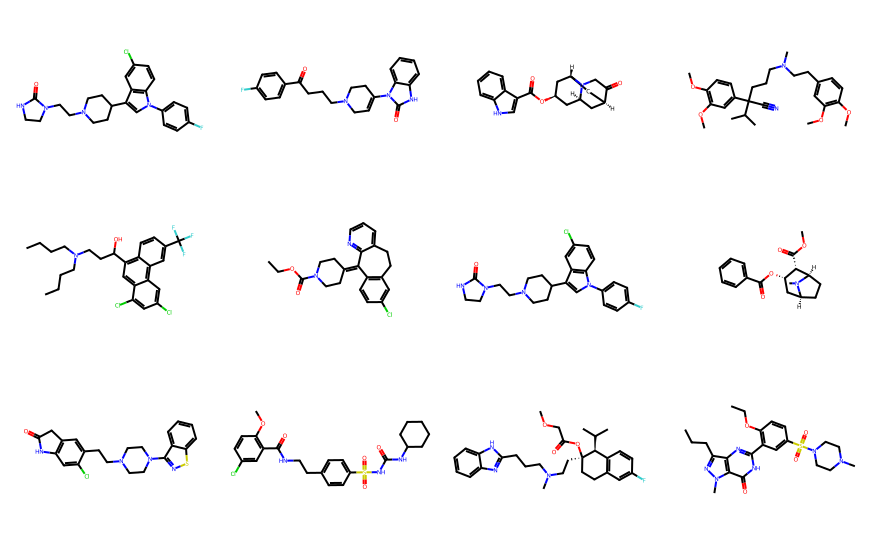

In [121]:
valid_molecules = df_clean["mol"].dropna().head(12).tolist()
display(Draw.MolsToGridImage(
    valid_molecules,
    molsPerRow=4,
    subImgSize=(220, 180),
))


### 5.1 Optional structure standardization

A record can contain a salt, an unusual protonation state, or a non-canonical representation. Here we demonstrate a conservative workflow: choose the largest fragment, normalize, reionize, uncharge, and sanitize.

Standardization is not universally correct. In a real project, the chosen rules should be documented because they can change the molecule and therefore its descriptors.


In [122]:
def standardize_mol(mol):
    """Apply a conservative, reproducible RDKit standardization."""
    if mol is None:
        return None
    try:
        fragments = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
        largest = max(fragments, key=Chem.Mol.GetNumHeavyAtoms)
        normalized = rdMolStandardize.Normalize(largest)
        reionized = rdMolStandardize.Reionize(normalized)
        uncharged = rdMolStandardize.Uncharger().uncharge(reionized)
        Chem.SanitizeMol(uncharged)
        return uncharged
    except Exception:
        return None


In [123]:
df_clean["mol"] = df_clean["mol"].map(standardize_mol)
df_clean = df_clean[df_clean["mol"].notna()].copy()
df_clean["canonical_smiles_rdkit"] = df_clean["mol"].map(Chem.MolToSmiles)

print("Valid standardized structures:", len(df_clean))


Valid standardized structures: 3433


## 6. Aggregate repeated measurements

Several assays may report pIC50 values for the same standardized structure. We use the median as a robust central estimate and retain the number of measurements and their standard deviation as quality information.

This turns an assay-level table into a molecule-level modeling table.


In [ ]:
aggregated = (
    df_clean.groupby("canonical_smiles_rdkit", as_index=False)
    .agg(
        pIC50=("pIC50", "median"),
        n_measurements=("pIC50", "size"),
        pIC50_sd=("pIC50", "std"),
        molecule_chembl_id=("molecule_chembl_id", "first"),
        molecule_name=("molecule_name", "first"),
    )
)
aggregated["pIC50_sd"] = aggregated["pIC50_sd"].fillna(0.0)
aggregated["mol"] = aggregated["canonical_smiles_rdkit"].map(Chem.MolFromSmiles)
aggregated = aggregated[aggregated["mol"].notna()].reset_index(drop=True)

print("Unique standardized molecules:", len(aggregated))
display(aggregated.head())


In [ ]:
display(
    aggregated["n_measurements"]
    .value_counts()
    .sort_index()
    .head(10)
    .rename("molecules")
    .to_frame()
)


In [ ]:
repeat_plot = px.histogram(
    aggregated,
    x="n_measurements",
    nbins=max(1, int(aggregated["n_measurements"].max())),
    title="Repeated measurements before aggregation",
    labels={"n_measurements": "Measurements per structure", "count": "Molecules"},
)
repeat_plot.update_layout(bargap=0.15)
repeat_plot.show()


## 7. Inspect the target distribution

Before fitting a model, inspect the response variable. A narrow target range, extreme outliers, or a large number of repeated measurements affects both model choice and interpretation of the metrics.


In [127]:
target_plot = px.histogram(
    aggregated,
    x="pIC50",
    nbins=25,
    title="Distribution of aggregated hERG potency",
    labels={"pIC50": "pIC50", "count": "Molecules"},
)
target_plot.show()


## 8. Calculate a few descriptors manually

A descriptor is a numerical function of molecular structure. Implementing a few simple examples makes the connection between a molecular graph and a feature vector explicit before using a descriptor library.

For example, molecular weight is the sum of atomic masses, while the number of aromatic atoms is a graph property calculated from atom flags.


In [128]:
from rdkit.Chem import Descriptors

def manual_molecular_weight(mol):
    return sum(atom.GetMass() for atom in mol.GetAtoms())

def manual_atom_count(mol):
    return mol.GetNumAtoms()

def manual_heteroatom_count(mol):
    return sum(atom.GetAtomicNum() not in (1, 6) for atom in mol.GetAtoms())

def manual_aromatic_atom_count(mol):
    return sum(atom.GetIsAromatic() for atom in mol.GetAtoms())


In [129]:
comparison_rows = []
for smiles in ["CCO", "c1ccccc1", "CC(=O)O"]:
    mol = Chem.MolFromSmiles(smiles)
    comparison_rows.append({
        "smiles": smiles,
        "manual_MolWt": manual_molecular_weight(mol),
        "RDKit_MolWt": Descriptors.MolWt(mol),
        "manual_atoms": manual_atom_count(mol),
        "manual_heteroatoms": manual_heteroatom_count(mol),
        "manual_aromatic_atoms": manual_aromatic_atom_count(mol),
    })

manual_comparison = pd.DataFrame(comparison_rows)
display(manual_comparison)
#assert np.allclose(manual_comparison["manual_MolWt"], manual_comparison["RDKit_MolWt"])


,smiles,manual_MolWt,RDKit_MolWt,manual_atoms,manual_heteroatoms,manual_aromatic_atoms
0,CCO,40.021,46.069,3,1,0
1,c1ccccc1,72.066,78.114,6,0,6
2,CC(=O)O,56.020,60.052,4,2,0


## 9. Build a small interpretable descriptor matrix

We start with descriptors that have an intuitive chemical interpretation:

- **MolWt**: molecular weight;
- **LogP**: estimated octanol/water partition coefficient;
- **TPSA**: topological polar surface area;
- **HBD/HBA**: hydrogen-bond donors/acceptors;
- **RotBonds**: rotatable bonds;
- **RingCount** and **FractionCSP3**: structural complexity and saturation-related features.


In [130]:
from rdkit.Chem import Descriptors, Lipinski

def small_descriptor_vector(mol):
    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotBonds": Lipinski.NumRotatableBonds(mol),
        "RingCount": Lipinski.RingCount(mol),
        "FractionCSP3": Descriptors.FractionCSP3(mol),
    }


In [131]:
X_small = pd.DataFrame(
    [small_descriptor_vector(mol) for mol in aggregated["mol"]]
).replace([np.inf, -np.inf], np.nan)
y = aggregated["pIC50"].to_numpy(dtype=float)

print("Small descriptor matrix:", X_small.shape)
display(X_small.head())


Small descriptor matrix: (2689, 8)


,MolWt,LogP,TPSA,HBD,HBA,RotBonds,RingCount,FractionCSP3
0,323.194,2.2697,45.40,0,5,1,5,0.538462
1,448.551,5.3847,55.73,1,4,5,6,0.111111
2,449.539,4.7797,68.62,1,5,5,6,0.115385
3,277.411,4.6005,3.24,0,1,2,3,0.300000
4,378.611,4.5904,39.99,1,5,4,4,0.789474


## 10. Explore descriptor relationships

Correlation is not causation, but it is useful for finding redundant features and simple relationships worth visualizing. We include the target in the correlation table only for exploration; it is not a substitute for held-out evaluation.


In [132]:


correlation_plot = px.imshow(
    X_small.corr(),
    zmin=-1,
    zmax=1,
    color_continuous_scale="RdBu_r",
    title="Static descriptor/target correlation",
    aspect="auto",
)
correlation_plot.show()


In [133]:
logp_plot_data = X_small.assign(
    pIC50=y,
    molecule_chembl_id=aggregated["molecule_chembl_id"].to_numpy(),
    molecule_name=aggregated["molecule_name"].to_numpy(),
    canonical_smiles_rdkit=aggregated["canonical_smiles_rdkit"].to_numpy(),
)
logp_plot = px.scatter(
    logp_plot_data,
    x="LogP",
    y="pIC50",
    hover_name="molecule_name",
    hover_data=["molecule_chembl_id", "canonical_smiles_rdkit", "pIC50"],
    title="mLogP versus hERG activity",
)
logp_plot.show()


## 11. Make one reproducible random split

Every representation will use the same molecule indices. Otherwise, a difference in test performance could come from a different test set rather than a better representation.

This is a random split, so close chemical analogues may appear in both sets. Later we will use a scaffold split to test extrapolation to new chemotypes.


In [134]:
indices = np.arange(len(aggregated))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
)
y = aggregated["pIC50"].to_numpy(dtype=float)

print(f"Random split: {len(train_idx)} train / {len(test_idx)} test")


Random split: 2151 train / 538 test


In [135]:
split_summary = pd.DataFrame({
    "split": ["train", "test"],
    "n": [len(train_idx), len(test_idx)],
    "mean_pIC50": [y[train_idx].mean(), y[test_idx].mean()],
    "sd_pIC50": [y[train_idx].std(), y[test_idx].std()],
})
display(split_summary)


,split,n,mean_pIC50,sd_pIC50
0,train,2151,5.512050,1.045450
1,test,538,5.476456,0.973098


# 11.5 Dynamic descriptor EDA before modeling

The precomputed PyL3DMD matrix is loaded and inspected here, before fitting the main QSAR models. This ordering lets us identify missing values, numerical outliers, correlation structure, and chemical neighbourhood patterns before evaluating predictive models.


In [ ]:
DYNAMIC_DIR = Path("../week10_dynamic")
if not DYNAMIC_DIR.exists():
    DYNAMIC_DIR = Path("practicals/week10_dynamic")
DYNAMIC_MATRIX_PATH = DYNAMIC_DIR / "pyl3dmd_dynamic_features.csv"
DYNAMIC_METADATA_PATH = DYNAMIC_DIR / "dynamic_descriptor_subset_150.csv"

print("Dynamic matrix:", DYNAMIC_MATRIX_PATH)
print("Dynamic metadata:", DYNAMIC_METADATA_PATH)
print("Matrix exists:", DYNAMIC_MATRIX_PATH.exists())
print("Metadata exists:", DYNAMIC_METADATA_PATH.exists())


In [ ]:
if not DYNAMIC_MATRIX_PATH.exists():
    raise FileNotFoundError(
        "The precomputed PyL3DMD matrix is missing. Run "
        "week10_dynamic/run_pyl3dmd_batch.py once first."
    )

dynamic_matrix = pd.read_csv(DYNAMIC_MATRIX_PATH)
dynamic_metadata = pd.read_csv(DYNAMIC_METADATA_PATH)
dynamic_descriptor_columns = [
    column for column in dynamic_matrix.columns
    if column != "dynamic_subset_id"
]

dynamic_table = dynamic_metadata[
    ["dynamic_subset_id", "molecule_chembl_id", "canonical_smiles_rdkit", "pIC50"]
].merge(dynamic_matrix, on="dynamic_subset_id", validate="one_to_one")
print("Saved PyL3DMD matrix:", dynamic_matrix.shape)
print(
    "Missing dynamic descriptor cells:",
    int(dynamic_matrix[dynamic_descriptor_columns].isna().sum().sum()),
)
print("Joined dynamic table:", dynamic_table.shape)
display(dynamic_table.iloc[:, :8].head())


### 20.1.1 Resolve molecule names for inspection

ChEMBL IDs are stable identifiers but are not always easy to read in a plot. We retrieve the preferred ChEMBL molecule name once, cache it locally, and fall back to the ChEMBL ID when a record has no preferred name or the service is unavailable. The chemical structure remains available in the hover data through the canonical SMILES.


In [ ]:
NAME_CACHE_PATH = DYNAMIC_DIR / "molecule_names.csv"

# The main QSAR table already resolved names. Reuse that mapping so
# that the dynamic join cannot create molecule_name_x/molecule_name_y.
if "molecule_name" in aggregated.columns:
    molecule_names = aggregated[[
        "molecule_chembl_id", "molecule_name"
    ]].drop_duplicates()
    molecule_names["name_source"] = "cached in aggregated table"
elif NAME_CACHE_PATH.exists():
    molecule_names = pd.read_csv(NAME_CACHE_PATH)
else:
    name_rows = []
    try:
        from chembl_webresource_client.new_client import new_client
        molecule_client = new_client.molecule
        for molecule_id in dynamic_metadata["molecule_chembl_id"].dropna().unique():
            try:
                record = molecule_client.get(molecule_id)
                preferred_name = record.get("pref_name")
            except Exception:
                preferred_name = None
            name_rows.append({
                "molecule_chembl_id": molecule_id,
                "molecule_name": preferred_name,
                "name_source": "ChEMBL preferred name" if preferred_name else "ChEMBL ID fallback",
            })
    except Exception as exc:
        print("ChEMBL name lookup unavailable:", exc)

    molecule_names = pd.DataFrame(name_rows)
    if molecule_names.empty:
        molecule_names = dynamic_metadata[["molecule_chembl_id"]].drop_duplicates().copy()
        molecule_names["molecule_name"] = molecule_names["molecule_chembl_id"]
        molecule_names["name_source"] = "ChEMBL ID fallback"
    molecule_names["molecule_name"] = molecule_names["molecule_name"].fillna(
        molecule_names["molecule_chembl_id"]
    )
    molecule_names.to_csv(NAME_CACHE_PATH, index=False)

if "molecule_name" not in dynamic_table.columns and "molecule_name" not in aggregated.columns:
    dynamic_table = dynamic_table.merge(
        molecule_names,
        on="molecule_chembl_id",
        how="left",
        validate="one_to_one",
    )
if "molecule_name" in dynamic_table.columns:
    dynamic_table["molecule_name"] = dynamic_table["molecule_name"].fillna(
        dynamic_table["molecule_chembl_id"]
    )
    display(dynamic_table[[
        "molecule_chembl_id", "molecule_name", "canonical_smiles_rdkit"
    ]].head())
else:
    display(aggregated[[
        "molecule_chembl_id", "molecule_name", "canonical_smiles_rdkit"
    ]].head())


### 20.1 Join dynamic descriptors to the standardized QSAR table

The dynamic subset was selected from the same standardized hERG data. We join by the canonical RDKit SMILES rather than relying on row order. This is a useful safeguard whenever a feature matrix has been generated in a separate workflow.


In [ ]:
dynamic_dataset = aggregated.merge(
    dynamic_table,
    on="canonical_smiles_rdkit",
    how="inner",
    suffixes=("_static", "_dynamic"),
    validate="one_to_one",
)
print("Molecules available for dynamic comparison:", len(dynamic_dataset))
print("Target agreement:", np.allclose(
    dynamic_dataset["pIC50_static"],
    dynamic_dataset["pIC50_dynamic"],
    equal_nan=False,
))
assert len(dynamic_dataset) > 0



**Step note.** First join the static and dynamic tables; then apply the numerical safety filter.

In [ ]:
def sanitize_dynamic_features(frame):
    """Make PyL3DMD values safe for scikit-learn tree validation."""
    cleaned = frame.apply(pd.to_numeric, errors="coerce")
    cleaned = cleaned.replace([np.inf, -np.inf], np.nan)

    # sklearn validates tree input as float32.  Also leave headroom for
    # the internal sum used during validation, not only individual casts.
    safe_limit = (
        np.finfo(np.float32).max
        / max(1, cleaned.shape[0] * cleaned.shape[1])
        * 0.5
    )
    cleaned = cleaned.mask(cleaned.abs() > safe_limit, np.nan)
    cleaned = cleaned.loc[:, cleaned.notna().any(axis=0)]
    print(
        f"Dynamic numerical safety limit: {safe_limit:.3e}; "
        f"usable columns: {cleaned.shape[1]}"
    )
    return cleaned

dynamic_static = pd.DataFrame(
    [small_descriptor_vector(mol) for mol in dynamic_dataset["mol"]]
).replace([np.inf, -np.inf], np.nan)
dynamic_pyl3dmd = sanitize_dynamic_features(
    dynamic_dataset[dynamic_descriptor_columns]
)
dynamic_target = dynamic_dataset["pIC50_static"].to_numpy(dtype=float)

dynamic_indices = np.arange(len(dynamic_dataset))
dynamic_target_bins = pd.qcut(
    dynamic_target,
    q=5,
    labels=False,
    duplicates="drop",
)
dynamic_train_idx, dynamic_test_idx = train_test_split(
    dynamic_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=dynamic_target_bins,
)
print(
    f"Dynamic comparison split: {len(dynamic_train_idx)} train / "
    f"{len(dynamic_test_idx)} test"
)


### 20.3 Interactive EDA: missing values, outliers, and correlations

Dynamic descriptor libraries calculate many different mathematical summaries. Missing values can arise when a descriptor is undefined for a particular geometry, when a denominator is zero, or when a numerical calculation becomes unstable. Extreme values can indicate a genuinely unusual conformation, but they can also signal an invalid or poorly conditioned descriptor calculation.

We inspect these issues before modeling. The plots are interactive: hover over a bar or point to inspect the feature name, molecule ID, SMILES, and target value.


In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

try:
    import umap.umap_ as umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False
    print("UMAP is not installed; the t-SNE plots will still be available.")



**Step note.** Calculate missing-value counts before drawing the interactive missingness plot.

In [ ]:
def missing_summary(frame, representation):
    result = frame.isna().sum().rename("missing").reset_index()
    result.columns = ["feature", "missing"]
    result["representation"] = representation
    result["missing_fraction"] = result["missing"] / len(frame)
    return result.sort_values("missing", ascending=False)

missing_static = missing_summary(dynamic_static, "static RDKit")
missing_dynamic = missing_summary(
    dynamic_table[dynamic_descriptor_columns],
    "PyL3DMD",
)
missing_all = pd.concat([missing_static, missing_dynamic], ignore_index=True)
print("Static missing cells:", int(missing_static["missing"].sum()))
print("PyL3DMD missing cells:", int(missing_dynamic["missing"].sum()))

missing_plot_data = missing_all[missing_all["missing"] > 0].head(30)
if not missing_plot_data.empty:
    fig = px.bar(
        missing_plot_data.sort_values("missing"),
        x="missing",
        y="feature",
        color="representation",
        orientation="h",
        hover_data=["missing_fraction"],
        title="Features with missing values",
    )
    fig.show()


**Step note.** Define the IQR rule and calculate feature-level outlier counts.

In [ ]:
def iqr_outlier_summary(frame, representation):
    numeric = frame.apply(pd.to_numeric, errors="coerce")
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    q1 = numeric.quantile(0.25)
    q3 = numeric.quantile(0.75)
    iqr = (q3 - q1).replace(0, np.nan)
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flags = numeric.lt(lower) | numeric.gt(upper)
    summary = pd.DataFrame({
        "feature": numeric.columns,
        "outlier_count": flags.sum(axis=0).to_numpy(),
        "outlier_fraction": flags.mean(axis=0).to_numpy(),
        "q1": q1.to_numpy(),
        "q3": q3.to_numpy(),
    })
    summary["representation"] = representation
    return summary.sort_values("outlier_count", ascending=False), flags

static_outliers, static_outlier_flags = iqr_outlier_summary(
    dynamic_static,
    "static RDKit",
)
dynamic_outliers, dynamic_outlier_flags = iqr_outlier_summary(
    dynamic_pyl3dmd,
    "PyL3DMD",
)
outlier_table = pd.concat([static_outliers, dynamic_outliers], ignore_index=True)
print("Static feature outlier flags:", int(static_outlier_flags.to_numpy().sum()))
print("PyL3DMD feature outlier flags:", int(dynamic_outlier_flags.to_numpy().sum()))

fig = px.bar(
    outlier_table.head(30).sort_values("outlier_count"),
    x="outlier_count",
    y="feature",
    color="representation",
    orientation="h",
    hover_data=["outlier_fraction", "q1", "q3"],
    title="Largest IQR-based outlier counts",
)
fig.show()



**Step note.** Now aggregate the feature-level flags to inspect which molecules are unusual.

In [ ]:
molecule_outliers = pd.DataFrame({
    "static_outlier_count": static_outlier_flags.sum(axis=1),
    "dynamic_outlier_count": dynamic_outlier_flags.sum(axis=1),
    "molecule_chembl_id": dynamic_dataset["molecule_chembl_id_static"].to_numpy(),
    "molecule_name": dynamic_dataset["molecule_name"].to_numpy(),
    "canonical_smiles_rdkit": dynamic_dataset["canonical_smiles_rdkit"].to_numpy(),
    "pIC50": dynamic_target,
})
fig = px.scatter(
    molecule_outliers,
    x="static_outlier_count",
    y="dynamic_outlier_count",
    color="pIC50",
    hover_name="molecule_name",
    hover_data=["molecule_chembl_id", "canonical_smiles_rdkit", "pIC50"],
    title="Molecule-level outlier counts",
    color_continuous_scale="Viridis",
)
fig.show()


### 20.4 Pearson, Spearman, and Kendall associations

- **Pearson correlation** measures linear association and is sensitive to extreme values.
- **Spearman correlation** correlates ranks, so it is less sensitive to monotonic outliers.
- **Kendall correlation** is based on concordant and discordant pairs and is useful for small samples, although it is slower.

A correlation is an exploratory association, not evidence that a descriptor causes the biological response. For the 7,000+ dynamic descriptors, we display correlations for the 20 descriptors with the largest usable variation and keep the full matrix out of the plot for readability.


In [ ]:
def feature_target_correlations(frame, target, representation, max_features=None):
    numeric = frame.apply(pd.to_numeric, errors="coerce")
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    if max_features is not None and numeric.shape[1] > max_features:
        usable_variation = numeric.std(skipna=True).sort_values(ascending=False)
        numeric = numeric[usable_variation.head(max_features).index]
    records = []
    target_series = pd.Series(target, index=numeric.index, name="pIC50")
    for feature in numeric.columns:
        pair = pd.concat([numeric[feature], target_series], axis=1).dropna()
        if len(pair) < 3 or pair.iloc[:, 0].nunique() < 2:
            continue
        for method in ["pearson", "spearman", "kendall"]:
            records.append({
                "feature": feature,
                "method": method,
                "correlation": pair.iloc[:, 0].corr(pair["pIC50"], method=method),
                "representation": representation,
            })
    return pd.DataFrame(records)

static_correlations = feature_target_correlations(
    dynamic_static,
    dynamic_target,
    "static RDKit",
)
dynamic_correlations = feature_target_correlations(
    dynamic_pyl3dmd,
    dynamic_target,
    "PyL3DMD",
    max_features=20,
)
correlations = pd.concat(
    [static_correlations, dynamic_correlations],
    ignore_index=True,
)
fig = px.scatter(
    correlations,
    x="feature",
    y="correlation",
    color="method",
    symbol="representation",
    hover_data=["representation", "method", "correlation"],
    title="Feature/target associations by correlation type",
)
fig.update_xaxes(tickangle=75)
fig.show()


**Step note.** The heatmaps are separate from the feature/target association table so each can be inspected independently.

In [ ]:
for method in ["pearson", "spearman", "kendall"]:
    corr_input = dynamic_static.copy()
    corr_input["pIC50"] = dynamic_target
    matrix = corr_input.corr(method=method)
    fig = px.imshow(
        matrix,
        zmin=-1,
        zmax=1,
        color_continuous_scale="RdBu_r",
        title=f"Static descriptors: {method.title()} correlation",
        aspect="auto",
    )
    fig.show()


### 20.4.1 Distance correlation and MIC-style association

Pearson, Spearman, and Kendall correlations summarize particular kinds of association. **Distance correlation** is zero only when two variables are independent in the population and can detect nonlinear relationships. It is bounded between 0 and 1, but it does not indicate the direction of an association.

The **maximal information coefficient (MIC)** searches over grid partitions to find a strong relationship even when its shape is not linear or monotonic. True MIC requires the optional `minepy` package. If `minepy` is unavailable, the cell uses scikit-learn mutual information as a clearly labelled fallback; mutual information and MIC are related ideas, but they are not numerically identical.


In [ ]:
import dcor
from sklearn.feature_selection import mutual_info_regression

try:
    from minepy import MINE
    HAS_MINEPY = True
except ImportError:
    MINE = None
    HAS_MINEPY = False
    print("minepy is unavailable; using mutual information as a labelled fallback for MIC.")

def nonlinear_association_table(frame, target, representation, max_features=20):
    numeric = frame.apply(pd.to_numeric, errors="coerce")
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    variation = numeric.std(skipna=True).sort_values(ascending=False)
    numeric = numeric[variation.head(max_features).index]
    records = []
    target_array = np.asarray(target, dtype=float)
    for feature in numeric.columns:
        values = numeric[feature].to_numpy(dtype=float)
        valid = np.isfinite(values) & np.isfinite(target_array)
        values = values[valid]
        target_values = target_array[valid]
        if len(values) < 5 or np.unique(values).size < 2:
            continue
        values = np.where(np.isfinite(values), values, np.nanmedian(values))
        distance_correlation = float(dcor.distance_correlation(values, target_values))
        if HAS_MINEPY:
            mine = MINE(alpha=0.6, c=15)
            mine.compute_score(values, target_values)
            information_score = float(mine.mic())
            information_method = "MIC (minepy)"
        else:
            scaled_values = StandardScaler().fit_transform(
                values.reshape(-1, 1)
            )
            information_score = float(
                mutual_info_regression(
                    scaled_values,
                    target_values,
                    random_state=SEED,
                )[0]
            )
            information_method = "mutual information fallback"
        records.append({
            "feature": feature,
            "representation": representation,
            "distance_correlation": distance_correlation,
            "information_score": information_score,
            "information_method": information_method,
        })
    return pd.DataFrame(records)



**Step note.** Calculate distance correlation and MIC or mutual-information scores for the selected features.

In [ ]:
nonlinear_associations = pd.concat([
    nonlinear_association_table(dynamic_static, dynamic_target, "static RDKit"),
    nonlinear_association_table(dynamic_pyl3dmd, dynamic_target, "PyL3DMD"),
], ignore_index=True)
display(nonlinear_associations.sort_values(
    ["representation", "distance_correlation"],
    ascending=[True, False],
).head(20))

distance_plot = px.bar(
    nonlinear_associations.sort_values("distance_correlation"),
    x="distance_correlation",
    y="feature",
    color="representation",
    orientation="h",
    hover_data=["information_score", "information_method"],
    title="Distance correlation with pIC50",
)
distance_plot.show()

information_plot = px.bar(
    nonlinear_associations.sort_values("information_score"),
    x="information_score",
    y="feature",
    color="representation",
    orientation="h",
    hover_data=["distance_correlation", "information_method"],
    title="MIC or mutual-information association with pIC50",
)
information_plot.show()


### 20.5 t-SNE and UMAP maps of the chemical subset

These maps show local or neighbourhood structure in descriptor space. They are visualization tools, not proof of clusters and not predictive validation. We standardize features and use PCA first to reduce numerical noise before t-SNE or UMAP.


In [ ]:
embedding_sources = {
    "static RDKit": dynamic_static,
    "PyL3DMD": dynamic_pyl3dmd,
    "static + PyL3DMD": pd.concat([dynamic_static, dynamic_pyl3dmd], axis=1),
}

def prepare_embedding_features(frame):
    imputed = SimpleImputer(strategy="median").fit_transform(frame)
    scaled = StandardScaler().fit_transform(imputed)
    n_components = min(30, scaled.shape[0] - 1, scaled.shape[1])
    return PCA(n_components=n_components, random_state=SEED).fit_transform(scaled)



**Step note.** Run the nonlinear embeddings after the PCA preparation step.

In [ ]:
embedding_frames = []
for representation, features in embedding_sources.items():
    reduced = prepare_embedding_features(features)
    perplexity = min(30, max(5, (len(reduced) - 1) // 3))
    tsne_coordinates = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        random_state=SEED,
    ).fit_transform(reduced)
    embedding_frame = pd.DataFrame({
        "tSNE_1": tsne_coordinates[:, 0],
        "tSNE_2": tsne_coordinates[:, 1],
        "representation": representation,
        "molecule_chembl_id": dynamic_dataset["molecule_chembl_id_static"].to_numpy(),
        "molecule_name": dynamic_dataset["molecule_name"].to_numpy(),
        "canonical_smiles_rdkit": dynamic_dataset["canonical_smiles_rdkit"].to_numpy(),
        "pIC50": dynamic_target,
    })
    embedding_frames.append(embedding_frame)

    fig = px.scatter(
        embedding_frame,
        x="tSNE_1",
        y="tSNE_2",
        color="pIC50",
        hover_name="molecule_name",
        hover_data=["molecule_chembl_id", "canonical_smiles_rdkit", "pIC50"],
        title=f"t-SNE: {representation}",
        color_continuous_scale="Viridis",
    )
    fig.show()

    if HAS_UMAP:
        umap_coordinates = umap.UMAP(
            n_neighbors=min(15, len(reduced) - 1),
            min_dist=0.1,
            random_state=SEED,
        ).fit_transform(reduced)
        umap_frame = embedding_frame.copy()
        umap_frame["UMAP_1"] = umap_coordinates[:, 0]
        umap_frame["UMAP_2"] = umap_coordinates[:, 1]
        fig = px.scatter(
            umap_frame,
            x="UMAP_1",
            y="UMAP_2",
            color="pIC50",
            hover_name="molecule_name",
            hover_data=["molecule_chembl_id", "canonical_smiles_rdkit", "pIC50"],
            title=f"UMAP: {representation}",
            color_continuous_scale="Viridis",
        )
        fig.show()


### 20.6 Animate one LAMMPS trajectory

A trajectory is a sequence of molecular geometries, not one additional row in the descriptor table. The cell below parses a bounded number of frames and renders them as an embedded GIF. A GIF is robust in Jupyter and Positron and is used for inspection rather than as a physical rendering of bonds.


In [ ]:
import gzip
import tempfile
import zipfile
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter

TRAJECTORY_MEMBER = "lammps_runs/molecule_0000/trajectory.lammpstrj"
TRAJECTORY_PATH = DYNAMIC_DIR / TRAJECTORY_MEMBER
BUNDLE_PATH = DYNAMIC_DIR / "lammps_dynamic_bundle.zip"

def locate_trajectory():
    """Find one trajectory whether it is unpacked or still in the bundle."""
    if TRAJECTORY_PATH.exists():
        return TRAJECTORY_PATH

    unpacked = sorted(
        path for pattern in ("*.lammpstrj", "*.dump", "*.lammpstrj.gz")
        for path in DYNAMIC_DIR.rglob(pattern)
    )
    if unpacked:
        return unpacked[0]

    if BUNDLE_PATH.exists():
        with zipfile.ZipFile(BUNDLE_PATH) as archive:
            members = [
                name for name in archive.namelist()
                if name.lower().endswith((".lammpstrj", ".dump", ".lammpstrj.gz"))
            ]
            if members:
                selected_member = sorted(members)[0]
                archive.extract(selected_member, path=DYNAMIC_DIR)
                print("Extracted trajectory:", selected_member)
                return DYNAMIC_DIR / selected_member
    return None

TRAJECTORY_PATH = locate_trajectory()



**Step note.** Parse the LAMMPS dump one frame at a time.

In [ ]:
def read_lammps_trajectory(path, max_frames=80):
    """Read common LAMMPS dump variants into a tidy atom/frame table."""
    rows = []
    open_function = gzip.open if str(path).lower().endswith(".gz") else Path.open
    open_arguments = {"mode": "rt", "encoding": "utf-8"} if open_function is gzip.open else {"mode": "r", "encoding": "utf-8"}
    with open_function(path, **open_arguments) as handle:
        frame_number = 0
        while True:
            line = handle.readline()
            if not line:
                break
            if line.strip() != "ITEM: TIMESTEP":
                continue
            timestep_line = handle.readline()
            number_header = handle.readline()
            number_line = handle.readline()
            if not timestep_line or not number_header or not number_line:
                break
            timestep = int(float(timestep_line.strip()))
            n_atoms = int(float(number_line.strip()))

            box_header = handle.readline()
            if not box_header:
                break
            if box_header.startswith("ITEM: BOX BOUNDS"):
                for _ in range(3):
                    handle.readline()
                atoms_header = handle.readline()
            else:
                # Be tolerant of a minimal dump without box bounds.
                atoms_header = box_header
            while atoms_header and not atoms_header.startswith("ITEM: ATOMS"):
                atoms_header = handle.readline()
            if not atoms_header:
                break

            columns = atoms_header.strip().split()[2:]
            values = [handle.readline().split() for _ in range(n_atoms)]
            index = {name: position for position, name in enumerate(columns)}
            if {"xu", "yu", "zu"}.issubset(index):
                coordinate_names = ("xu", "yu", "zu")
            elif {"x", "y", "z"}.issubset(index):
                coordinate_names = ("x", "y", "z")
            elif {"xs", "ys", "zs"}.issubset(index):
                coordinate_names = ("xs", "ys", "zs")
            else:
                raise ValueError(
                    "LAMMPS dump has no supported coordinate columns; found "
                    f"{columns}"
                )
            for atom_position, value in enumerate(values):
                if len(value) < len(columns):
                    continue
                rows.append({
                    "frame": frame_number,
                    "timestep": timestep,
                    "id": int(float(value[index["id"]])) if "id" in index else atom_position,
                    "type": str(value[index["type"]]) if "type" in index else "unknown",
                    "x": float(value[index[coordinate_names[0]]]),
                    "y": float(value[index[coordinate_names[1]]]),
                    "z": float(value[index[coordinate_names[2]]]),
                })
            frame_number += 1
            if max_frames is not None and frame_number >= max_frames:
                break
    return pd.DataFrame(rows)



**Step note.** Render the parsed trajectory as a bounded local Matplotlib animation and inspect its radius of gyration.

In [ ]:
if TRAJECTORY_PATH is not None:
    trajectory_table = read_lammps_trajectory(TRAJECTORY_PATH, max_frames=80)
    print("Trajectory table:", trajectory_table.shape)

    if trajectory_table.empty:
        raise ValueError("The trajectory file was found, but it contained no atom rows.")

    # Keep one stable colour per atom type and sort atoms by ID in every
    # frame. This avoids the common animation bug where colours or atoms
    # jump because LAMMPS changes the row order between frames.
    trajectory_table = trajectory_table.sort_values(["frame", "id"])
    frame_groups = {
        frame: group.reset_index(drop=True)
        for frame, group in trajectory_table.groupby("frame", sort=True)
    }
    frame_numbers = list(frame_groups)
    type_labels = sorted(trajectory_table["type"].astype(str).unique())
    type_codes = {label: code for code, label in enumerate(type_labels)}
    colour_map = plt.get_cmap("tab20", max(1, len(type_labels)))

    figure = plt.figure(figsize=(7, 6))
    axis = figure.add_subplot(111, projection="3d")
    first_frame = frame_groups[frame_numbers[0]]
    first_codes = np.array([type_codes[str(value)] for value in first_frame["type"]])
    points = axis.scatter(
        first_frame["x"].to_numpy(),
        first_frame["y"].to_numpy(),
        first_frame["z"].to_numpy(),
        c=first_codes,
        cmap="tab20",
        s=25,
    )
    coordinate_min = trajectory_table[["x", "y", "z"]].min()
    coordinate_max = trajectory_table[["x", "y", "z"]].max()
    coordinate_span = (coordinate_max - coordinate_min).replace(0, 1.0)
    axis.set(
        xlim=(coordinate_min["x"] - 0.05 * coordinate_span["x"], coordinate_max["x"] + 0.05 * coordinate_span["x"]),
        ylim=(coordinate_min["y"] - 0.05 * coordinate_span["y"], coordinate_max["y"] + 0.05 * coordinate_span["y"]),
        zlim=(coordinate_min["z"] - 0.05 * coordinate_span["z"], coordinate_max["z"] + 0.05 * coordinate_span["z"]),
        xlabel="x", ylabel="y", zlabel="z",
    )
    axis.set_box_aspect((1, 1, 1))

    def update(frame_number):
        current = frame_groups[frame_number]
        current_codes = np.array([type_codes[str(value)] for value in current["type"]])
        points._offsets3d = (
            current["x"].to_numpy(),
            current["y"].to_numpy(),
            current["z"].to_numpy(),
        )
        points.set_facecolor(colour_map(current_codes))
        axis.set_title(f"LAMMPS molecule trajectory - frame {frame_number}")
        return (points,)

    animation = FuncAnimation(
        figure,
        update,
        frames=frame_numbers,
        interval=100,
        blit=False,
        cache_frame_data=False,
    )
    # A GIF is more reliable than a JavaScript animation in Jupyter and
    # Positron, and Pillow avoids an external ffmpeg dependency.
    with tempfile.TemporaryDirectory() as temporary_directory:
        gif_path = Path(temporary_directory) / "trajectory.gif"
        animation.save(gif_path, writer=PillowWriter(fps=10))
        display(Image(filename=str(gif_path)))
    plt.close(figure)

    radius_rows = []
    for frame, group in trajectory_table.groupby("frame"):
        coordinates = group[["x", "y", "z"]].to_numpy()
        centred = coordinates - coordinates.mean(axis=0, keepdims=True)
        radius_rows.append({
            "frame": frame,
            "radius_of_gyration": np.sqrt(np.mean(np.sum(centred ** 2, axis=1))),
        })
    radius_table = pd.DataFrame(radius_rows)
    radius_plot = px.line(
        radius_table,
        x="frame",
        y="radius_of_gyration",
        markers=True,
        title="Radius of gyration across the trajectory",
    )
    radius_plot.show()
else:
    print(
        "No LAMMPS trajectory found. Place a .lammpstrj/.dump file or "
        "lammps_dynamic_bundle.zip next to the dynamic matrix."
    )


## 12. Baseline QSAR models

We compare a linear regularized model with a nonlinear tree ensemble. The evaluation helper returns RMSE, MAE, R², and Spearman correlation:

\[
RMSE = \sqrt{\frac{1}{n}\sum_i (y_i-\hat y_i)^2}.
\]

The model is fit only on `train_idx`; the test set is used once for the comparison.


In [154]:
def regression_metrics(y_true, y_pred):
    return {
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "Spearman": pd.Series(y_true).corr(pd.Series(y_pred), method="spearman"),
    }

def fit_evaluate_model(model, X, train_indices, test_indices, representation, split_name="random"):
    X_train = X.iloc[train_indices] if isinstance(X, pd.DataFrame) else X[train_indices]
    X_test = X.iloc[test_indices] if isinstance(X, pd.DataFrame) else X[test_indices]
    y_train, y_test = y[train_indices], y[test_indices]
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    metrics = regression_metrics(y_test, predictions)
    metrics.update({"Representation": representation, "Model": type(model).__name__, "Split": split_name})
    return model, predictions, metrics


In [155]:
results = []
fitted_models = {}

small_models = {
    "small_Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0)),
    ]),
    "small_RF": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=SEED,
            n_jobs=-1,
        )),
    ]),
}


small_models["small_XGB"] = XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=2)


In [156]:
for name, model in small_models.items():
    fitted, predictions, metrics = fit_evaluate_model(
        model,
        X_small,
        train_idx,
        test_idx,
        "small descriptors",
    )
    fitted_models[name] = (fitted, predictions)
    results.append(metrics)

random_results = pd.DataFrame(results)
display(random_results.sort_values("RMSE"))


,RMSE,MAE,R2,Spearman,Representation,Model,Split
1,0.790600,0.558645,0.339914,0.572086,small descriptors,Pipeline,random
2,0.802141,0.583210,0.320502,0.520802,small descriptors,XGBRegressor,random
0,0.904602,0.652045,0.135825,0.387513,small descriptors,Pipeline,random


In [157]:
from sklearn.model_selection import KFold, RandomizedSearchCV

tuning_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
tuning_searches = {
    "tuned_RF": RandomizedSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1)),
        ]),
        param_distributions={
            "model__n_estimators": [200, 400, 700],
            "model__max_depth": [None, 5, 10, 20],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.7, 1.0],
        },
        n_iter=8,
        scoring="neg_root_mean_squared_error",
        cv=tuning_cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
    ),
}

if HAS_XGB:
    tuning_searches["tuned_XGB"] = RandomizedSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBRegressor(
                objective="reg:squarederror",
                random_state=SEED,
                n_jobs=2,
            )),
        ]),
        param_distributions={
            "model__n_estimators": [200, 400, 700],
            "model__max_depth": [2, 3, 5],
            "model__learning_rate": [0.02, 0.05, 0.1],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__min_child_weight": [1, 3, 6],
        },
        n_iter=8,
        scoring="neg_root_mean_squared_error",
        cv=tuning_cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
    )
print("Searches:", list(tuning_searches))


Searches: ['tuned_RF', 'tuned_XGB']


In [158]:
tuned_results = []
tuning_cv_tables = {}
for name, search in tuning_searches.items():
    search.fit(X_small.iloc[train_idx], y[train_idx])
    predictions = search.predict(X_small.iloc[test_idx])
    metrics = regression_metrics(y[test_idx], predictions)
    metrics.update({
        "Representation": "small descriptors, tuned",
        "Model": name,
        "Split": "random",
    })
    tuned_results.append(metrics)
    fitted_models[name] = (search.best_estimator_, predictions)
    tuning_cv_tables[name] = pd.DataFrame(search.cv_results_)
    print(name, "best parameters:", search.best_params_)

tuned_results_df = pd.DataFrame(tuned_results)
display(tuned_results_df.sort_values("RMSE"))
results.extend(tuned_results)


tuned_RF best parameters: {'model__n_estimators': 200, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': 20}
tuned_XGB best parameters: {'model__subsample': 1.0, 'model__n_estimators': 700, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}


,RMSE,MAE,R2,Spearman,Representation,Model,Split
0,0.794640,0.561235,0.333151,0.555590,"small descriptors, tuned",tuned_RF,random
1,0.832877,0.584882,0.267430,0.513903,"small descriptors, tuned",tuned_XGB,random


In [159]:
for name, cv_table in tuning_cv_tables.items():
    search_plot = px.scatter(
        cv_table,
        x="param_model__n_estimators",
        y=-cv_table["mean_test_score"],
        color="rank_test_score",
        hover_data=["params", "std_test_score"],
        title=f"Cross-validation search: {name}",
        labels={"y": "CV RMSE", "param_model__n_estimators": "Number of trees"},
    )
    search_plot.show()


## 12.5 Why hyperparameter tuning matters

A model's default settings are not a scientific baseline for every dataset. For Random Forests, tree depth, the number of trees, feature subsampling, and minimum leaf size control variance, computation, and smoothness. For XGBoost, learning rate, number of boosting rounds, tree depth, row subsampling, and column subsampling control the bias–variance trade-off.

We tune on the training data only using cross-validation. The held-out test set is evaluated only after the search finishes. The preprocessing steps are inside the same pipeline, so imputation and transformations are also learned only from each training fold.


In [ ]:
from sklearn.model_selection import KFold, RandomizedSearchCV

tuning_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
tuning_searches = {
    "tuned_RF": RandomizedSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1)),
        ]),
        param_distributions={
            "model__n_estimators": [200, 400, 700],
            "model__max_depth": [None, 5, 10, 20],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.7, 1.0],
        },
        n_iter=8,
        scoring="neg_root_mean_squared_error",
        cv=tuning_cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
    ),
}

if HAS_XGB:
    tuning_searches["tuned_XGB"] = RandomizedSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBRegressor(
                objective="reg:squarederror",
                random_state=SEED,
                n_jobs=2,
            )),
        ]),
        param_distributions={
            "model__n_estimators": [200, 400, 700],
            "model__max_depth": [2, 3, 5],
            "model__learning_rate": [0.02, 0.05, 0.1],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__min_child_weight": [1, 3, 6],
        },
        n_iter=8,
        scoring="neg_root_mean_squared_error",
        cv=tuning_cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
    )
print("Searches:", list(tuning_searches))


In [ ]:
tuned_results = []
tuning_cv_tables = {}
for name, search in tuning_searches.items():
    search.fit(X_small.iloc[train_idx], y[train_idx])
    predictions = search.predict(X_small.iloc[test_idx])
    metrics = regression_metrics(y[test_idx], predictions)
    metrics.update({
        "Representation": "small descriptors, tuned",
        "Model": name,
        "Split": "random",
    })
    tuned_results.append(metrics)
    fitted_models[name] = (search.best_estimator_, predictions)
    tuning_cv_tables[name] = pd.DataFrame(search.cv_results_)
    print(name, "best parameters:", search.best_params_)

tuned_results_df = pd.DataFrame(tuned_results)
display(tuned_results_df.sort_values("RMSE"))
results.extend(tuned_results)


In [ ]:
for name, cv_table in tuning_cv_tables.items():
    search_plot = px.scatter(
        cv_table,
        x="param_model__n_estimators",
        y=-cv_table["mean_test_score"],
        color="rank_test_score",
        hover_data=["params", "std_test_score"],
        title=f"Cross-validation search: {name}",
        labels={"y": "CV RMSE", "param_model__n_estimators": "Number of trees"},
    )
    search_plot.show()


## 12.6 Leakage-safe normalization, PCA, and transformations

Transformations are not interchangeable across model families. Trees are usually insensitive to feature scale, while Ridge regression and PCA depend strongly on scale. Molecular descriptors can also be skewed, so a Yeo–Johnson power transformation can make their distributions easier for linear models to use.

Every transformation below is inside a `Pipeline`. During cross-validation or a train/test comparison, its parameters are fitted on the training data only. Applying scaling or PCA to the full dataset before splitting would leak information from the test set.


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import PowerTransformer

transformed_models = {
    "scaled_Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("power", PowerTransformer(method="yeo-johnson", standardize=False)),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0)),
    ]),
    "scaled_PCA_Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("power", PowerTransformer(method="yeo-johnson", standardize=False)),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, whiten=True, random_state=SEED)),
        ("model", Ridge(alpha=1.0)),
    ]),
    "scaled_PCA_RF": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, random_state=SEED)),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=SEED,
            n_jobs=-1,
        )),
    ]),
}
transformed_results = []
for name, model in transformed_models.items():
    model.fit(X_small.iloc[train_idx], y[train_idx])
    predictions = model.predict(X_small.iloc[test_idx])
    metrics = regression_metrics(y[test_idx], predictions)
    metrics.update({
        "Representation": "small descriptors with transformations",
        "Model": name,
        "Split": "random",
    })
    transformed_results.append(metrics)
transformed_results_df = pd.DataFrame(transformed_results)
display(transformed_results_df.sort_values("RMSE"))
results.extend(transformed_results)


## 13. Calculate the full RDKit descriptor space

RDKit exposes many descriptors. A larger feature set can contain useful information, but also introduces missing values, constant columns, highly correlated features, and a greater risk of overfitting.


In [164]:
descriptor_functions = Descriptors.descList

def all_rdkit_descriptors(mol):
    values = {}
    for name, function in descriptor_functions:
        try:
            values[name] = float(function(mol))
        except Exception:
            values[name] = np.nan
    return values


In [165]:
X_rdkit = pd.DataFrame([all_rdkit_descriptors(mol) for mol in aggregated["mol"]])
X_rdkit = X_rdkit.replace([np.inf, -np.inf], np.nan)
print("full RDKit descriptor matrix:", X_rdkit.shape)
print("columns with missing values:", int(X_rdkit.isna().any().sum()))


full RDKit descriptor matrix: (2689, 217)
columns with missing values: 0


### 13.1 Filter descriptors using training data only

The filtering procedure is fitted on the training portion. This prevents the test set from influencing which columns are retained. We remove invalid columns, impute missing values with training medians, remove zero-variance columns, and remove one feature from highly correlated pairs.


In [166]:
def filter_descriptor_features(X_train, X_test, correlation_threshold=0.95):
    train = X_train.copy().replace([np.inf, -np.inf], np.nan)
    test = X_test.copy().replace([np.inf, -np.inf], np.nan)
    valid_columns = train.columns[train.notna().any(axis=0)]
    train, test = train[valid_columns], test[valid_columns]

    imputer = SimpleImputer(strategy="median")
    train_imputed = pd.DataFrame(imputer.fit_transform(train), columns=train.columns, index=train.index)
    test_imputed = pd.DataFrame(imputer.transform(test), columns=train.columns, index=test.index)

    variance_filter = VarianceThreshold(threshold=0.0)
    train_var = variance_filter.fit_transform(train_imputed)
    test_var = variance_filter.transform(test_imputed)
    kept_columns = train_imputed.columns[variance_filter.get_support()]
    train_var = pd.DataFrame(train_var, columns=kept_columns, index=train.index)
    test_var = pd.DataFrame(test_var, columns=kept_columns, index=test.index)

    correlation = train_var.corr().abs()
    upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
    dropped = [column for column in upper.columns if (upper[column] > correlation_threshold).any()]
    kept = [column for column in train_var.columns if column not in dropped]
    return train_var[kept], test_var[kept], kept


In [167]:
X_rdkit_train, X_rdkit_test, rdkit_feature_names = filter_descriptor_features(
    X_rdkit.iloc[train_idx], X_rdkit.iloc[test_idx]
)
print(f"filtered RDKit features: {len(rdkit_feature_names)}")



filtered RDKit features: 169


In [168]:
rdkit_model = RandomForestRegressor(n_estimators=400, random_state=SEED, n_jobs=-1)
rdkit_model.fit(X_rdkit_train, y[train_idx])
rdkit_predictions = rdkit_model.predict(X_rdkit_test)
rdkit_metrics = regression_metrics(y[test_idx], rdkit_predictions)
rdkit_metrics.update({"Representation": "full RDKit descriptors", "Model": "RandomForestRegressor", "Split": "random"})
results.append(rdkit_metrics)
fitted_models["rdkit_RF"] = (rdkit_model, rdkit_predictions)
print(rdkit_metrics)


{'RMSE': 0.6617828241594467, 'MAE': 0.4798771208181247, 'R2': 0.5374936686239715, 'Spearman': np.float64(0.6705837850352102), 'Representation': 'full RDKit descriptors', 'Model': 'RandomForestRegressor', 'Split': 'random'}


## 14. Morgan / ECFP fingerprints

A Morgan fingerprint records local circular neighborhoods around atoms. With radius 2, each bit summarizes information up to two bonds away from an atom; `fpSize` controls the length of the hashed binary vector.

Unlike descriptors such as TPSA, individual fingerprint bits do not usually have a simple one-column chemical interpretation. They are useful because they preserve substructure similarity.


In [169]:
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

MORGAN_SIZE = 2048
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=MORGAN_SIZE)


In [170]:
def morgan_array(mol):
    fingerprint = morgan_generator.GetFingerprint(mol)
    array = np.zeros((MORGAN_SIZE,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fingerprint, array)
    return array


In [171]:
X_morgan = np.vstack([morgan_array(mol) for mol in aggregated["mol"]])
print("Morgan matrix:", X_morgan.shape)


Morgan matrix: (2689, 2048)


### 14.1 Train a fingerprint baseline

We again reuse the random split. A Random Forest can work directly with the binary fingerprint matrix.


In [172]:
morgan_model = RandomForestRegressor(
    n_estimators=500,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=-1,
)


In [173]:
morgan_model.fit(X_morgan[train_idx], y[train_idx])
morgan_predictions = morgan_model.predict(X_morgan[test_idx])
morgan_metrics = regression_metrics(y[test_idx], morgan_predictions)
morgan_metrics.update({"Representation": "Morgan fingerprints", "Model": "RandomForestRegressor", "Split": "random"})
results.append(morgan_metrics)
fitted_models["morgan_RF"] = (morgan_model, morgan_predictions)
print(morgan_metrics)


{'RMSE': 0.6387864089890076, 'MAE': 0.4692393434743683, 'R2': 0.5690786275318515, 'Spearman': np.float64(0.6594636177170913), 'Representation': 'Morgan fingerprints', 'Model': 'RandomForestRegressor', 'Split': 'random'}


## 15. Tanimoto similarity and nearest chemical neighbours

For binary fingerprints, the Tanimoto coefficient is

\[
T(A,B)=\frac{|A\cap B|}{|A|+|B|-|A\cap B|}.
\]

A high nearest-neighbour similarity means that a test molecule is close to at least one training molecule in the chosen fingerprint space. This helps us interpret whether a prediction is interpolation or extrapolation.


In [174]:
def tanimoto_similarity(mol_a, mol_b):
    fp_a = morgan_generator.GetFingerprint(mol_a)
    fp_b = morgan_generator.GetFingerprint(mol_b)
    return DataStructs.TanimotoSimilarity(fp_a, fp_b)


In [175]:
test_position = int(test_idx[0])
test_mol = aggregated.loc[test_position, "mol"]
neighbour_rows = []
for train_position in train_idx:
    train_mol = aggregated.loc[int(train_position), "mol"]
    neighbour_rows.append({
        "train_index": int(train_position),
        "smiles": aggregated.loc[int(train_position), "canonical_smiles_rdkit"],
        "pIC50": y[int(train_position)],
        "Tanimoto": tanimoto_similarity(test_mol, train_mol),
    })
nearest_neighbours = pd.DataFrame(neighbour_rows).sort_values("Tanimoto", ascending=False).head(5)
print("test molecule:", aggregated.loc[test_position, "canonical_smiles_rdkit"])
display(nearest_neighbours)


test molecule: CS(=O)(=O)c1ccc(-c2noc(C3CCN(C(=O)NC4CC4c4ccccc4)CC3)n2)cc1


,train_index,smiles,pIC50,Tanimoto
1777,2341,O=C(NC1CC1c1ccccc1)N1CCC(c2nc(-c3cccnc3)no2)CC1,5.698970,0.701493
1341,2339,O=C(NC1CC1c1ccccc1)N1CCC(c2nc(-c3ccc4ccccc4n3)...,5.585027,0.652174
592,2340,O=C(NC1CC1c1ccccc1)N1CCC(c2nc(-c3ccccc3C(F)(F)...,5.221849,0.642857
754,2344,O=C(NC1CC1c1ccccc1)N1CCC(c2nc(-c3nccc4ccccc34)...,5.154902,0.633803
1645,2345,O=C(NC1CC1c1ccccc1)N1CCC(c2nc3ccccc3o2)CC1,5.086186,0.558824


## 16. Bemis–Murcko scaffolds

A random split can put close analogues, and even the same core scaffold, in both train and test. Bemis–Murcko scaffolds provide a simple grouping based on the core ring/linker framework of a molecule.


In [176]:
from rdkit.Chem.Scaffolds import MurckoScaffold

def murcko_scaffold_smiles(mol):
    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    return Chem.MolToSmiles(scaffold, canonical=True)


In [177]:
aggregated["scaffold"] = aggregated["mol"].map(murcko_scaffold_smiles)
print("unique scaffolds:", aggregated["scaffold"].nunique())
display(aggregated[["canonical_smiles_rdkit", "scaffold"]].head())


unique scaffolds: 1440


,canonical_smiles_rdkit,scaffold
0,Brc1cnc2nc(N3CCN4CCC3CC4)oc2c1,c1cnc2nc(N3CCN4CCC3CC4)oc2c1
1,C(#Cc1cc(-c2n[nH]c3c2Cc2cc(Cn4ccnc4)ccc2-3)cs1...,C(#Cc1cc(-c2n[nH]c3c2Cc2cc(Cn4ccnc4)ccc2-3)cs1...
2,C(#Cc1cc(-c2n[nH]c3c2Cc2cc(Cn4cncn4)ccc2-3)cs1...,C(#Cc1cc(-c2n[nH]c3c2Cc2cc(Cn4cncn4)ccc2-3)cs1...
3,C/C=C1/N(C)C(C)CC1(c1ccccc1)c1ccccc1,C=C1NCCC1(c1ccccc1)c1ccccc1
4,C1=C(CS/C(=N\C2CCCCC2)NC2CCCCC2)N2CCN=C2S1,C1=C(CS/C(=N\C2CCCCC2)NC2CCCCC2)N2CCN=C2S1


## 17. Scaffold-stratified split

Here we deliberately use the reverse of a scaffold-holdout split. Molecules are divided **within each Bemis–Murcko scaffold group**, so sufficiently large scaffold groups are represented in train, validation, and test.

1. For each molecule, RDKit calculates a Bemis–Murcko scaffold: the ring systems and the linkers connecting them, with peripheral substituents removed.
2. Molecules sharing the same scaffold form a stratum.
3. Each stratum is split approximately 80%, 10%, and 10% into train, validation, and test.
4. Scaffolds with at least three molecules are required to occur in all three sets.

\[
n_{s,train}+n_{s,val}+n_{s,test}=n_s.
\]

This split is useful for checking whether the representation works consistently across scaffold families, but it is **not** a test of extrapolation to unseen chemical cores. Because the same scaffold can appear in train and test, analogue leakage is possible. Use the earlier random split or a true scaffold-holdout split when the scientific question is generalization to new scaffolds.


In [178]:
def scaffold_split(
    df,
    scaffold_col="scaffold",
    train_frac=0.8,
    val_frac=0.1,
    random_state=SEED,
):
    """Stratify molecules within each scaffold group."""
    if not 0 < train_frac < 1 or not 0 <= val_frac < 1:
        raise ValueError("train_frac and val_frac must be valid fractions")
    test_frac = 1.0 - train_frac - val_frac
    if test_frac <= 0:
        raise ValueError("train_frac + val_frac must be less than 1")

    positions = pd.DataFrame({
        "position": np.arange(len(df), dtype=int),
        "scaffold": df[scaffold_col].to_numpy(),
    })
    grouped = positions.groupby("scaffold", dropna=False, sort=False)
    rng = np.random.default_rng(random_state)
    fractions = np.array([train_frac, val_frac, test_frac], dtype=float)
    assigned = [[], [], []]
    for _, group in grouped:
        molecule_positions = group["position"].to_numpy(dtype=int)
        rng.shuffle(molecule_positions)
        n_molecules = len(molecule_positions)
        raw_counts = fractions * n_molecules
        counts = np.floor(raw_counts).astype(int)

        # Ensure every scaffold with at least three molecules is
        # represented in every split, then distribute the remainder
        # according to the largest fractional parts.
        if n_molecules >= 3:
            counts = np.maximum(counts, 1)
        while counts.sum() > n_molecules:
            removable = np.where(
                counts > (1 if n_molecules >= 3 else 0)
            )[0]
            index = removable[np.argmax(counts[removable])]
            counts[index] -= 1
        for index in np.argsort(-(raw_counts - counts)):
            if counts.sum() >= n_molecules:
                break
            counts[index] += 1

        start = 0
        for split_index, count in enumerate(counts):
            stop = start + int(count)
            assigned[split_index].extend(
                molecule_positions[start:stop].tolist()
            )
            start = stop

    return tuple(
        np.array(sorted(values), dtype=int)
        for values in assigned
    )


In [179]:
scaffold_train_idx, scaffold_val_idx, scaffold_test_idx = scaffold_split(
    aggregated,
    random_state=SEED,
)
split_indices = {
    "train": scaffold_train_idx,
    "validation": scaffold_val_idx,
    "test": scaffold_test_idx,
}
for split_name, indices in split_indices.items():
    print(
        f"{split_name}: {len(indices)} molecules, "
        f"{aggregated.iloc[indices]['scaffold'].nunique()} unique scaffolds"
    )

scaffold_presence = pd.DataFrame({
    "scaffold": aggregated["scaffold"],
    "train": np.isin(np.arange(len(aggregated)), scaffold_train_idx),
    "validation": np.isin(np.arange(len(aggregated)), scaffold_val_idx),
    "test": np.isin(np.arange(len(aggregated)), scaffold_test_idx),
}).groupby("scaffold").sum()
scaffold_sizes = aggregated["scaffold"].value_counts()
large_scaffolds = scaffold_sizes[scaffold_sizes >= 3].index
fully_represented = scaffold_presence.loc[large_scaffolds].all(axis=1)
print(
    "Scaffolds represented in all three sets:",
    int(fully_represented.sum()),
    "/",
    len(large_scaffolds),
)
assert fully_represented.all()


train: 2229 molecules, 1440 unique scaffolds
validation: 232 molecules, 215 unique scaffolds
test: 228 molecules, 215 unique scaffolds
Scaffolds represented in all three sets: 215 / 215


## 18. Compare random and scaffold evaluation

We now repeat selected models on the scaffold-stratified test set. The representation and model are kept comparable; only the split changes.


In [180]:
scaffold_models = {
    "small descriptors": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ]),
    "Morgan fingerprints": RandomForestRegressor(
        n_estimators=500, max_features="sqrt", random_state=SEED, n_jobs=-1
    ),
}


In [181]:
for representation, model in scaffold_models.items():
    X_representation = X_small if representation == "small descriptors" else X_morgan
    X_train = X_representation.iloc[scaffold_train_idx] if isinstance(X_representation, pd.DataFrame) else X_representation[scaffold_train_idx]
    X_test = X_representation.iloc[scaffold_test_idx] if isinstance(X_representation, pd.DataFrame) else X_representation[scaffold_test_idx]
    model.fit(X_train, y[scaffold_train_idx])
    predictions = model.predict(X_test)
    metrics = regression_metrics(y[scaffold_test_idx], predictions)
    metrics.update({"Representation": representation, "Model": type(model).__name__, "Split": "scaffold"})
    results.append(metrics)


In [182]:
results_so_far = pd.DataFrame(results)
display(results_so_far.sort_values(["Split", "RMSE"]))


,RMSE,MAE,R2,Spearman,Representation,Model,Split
11,0.638786,0.469239,0.569079,0.659464,Morgan fingerprints,RandomForestRegressor,random
10,0.661783,0.479877,0.537494,0.670584,full RDKit descriptors,RandomForestRegressor,random
1,0.790600,0.558645,0.339914,0.572086,small descriptors,Pipeline,random
3,0.794640,0.561235,0.333151,0.555590,"small descriptors, tuned",tuned_RF,random
5,0.794640,0.561235,0.333151,0.555590,"small descriptors, tuned",tuned_RF,random
2,0.802141,0.583210,0.320502,0.520802,small descriptors,XGBRegressor,random
4,0.832877,0.584882,0.267430,0.513903,"small descriptors, tuned",tuned_XGB,random
6,0.832877,0.584882,0.267430,0.513903,"small descriptors, tuned",tuned_XGB,random
9,0.885864,0.612185,0.171255,0.461624,small descriptors with transformations,scaled_PCA_RF,random
0,0.904602,0.652045,0.135825,0.387513,small descriptors,Pipeline,random


## 19. Applicability domain

A simple applicability-domain diagnostic is the maximum similarity between a query molecule and any training molecule:

\[
S_i=\max_{j\in train} T(i,j).
\]

We compare this similarity with the absolute prediction error. A pattern of larger errors at low similarity suggests that the model is extrapolating beyond its training chemistry.


In [183]:
def nearest_train_similarity(test_mol, train_mols):
    fp_test = morgan_generator.GetFingerprint(test_mol)
    similarities = [
        DataStructs.TanimotoSimilarity(fp_test, morgan_generator.GetFingerprint(mol))
        for mol in train_mols
    ]
    return max(similarities) if similarities else np.nan


In [184]:
train_mols = aggregated.loc[train_idx, "mol"].tolist()
small_test_predictions = fitted_models["small_RF"][1]
applicability = pd.DataFrame({
    "nearest_train_similarity": [
        nearest_train_similarity(aggregated.loc[index, "mol"], train_mols)
        for index in test_idx
    ],
    "absolute_error": np.abs(y[test_idx] - small_test_predictions),
})
display(applicability.describe())


,nearest_train_similarity,absolute_error
count,538.000000,538.000000
mean,0.733294,0.558645
std,0.172743,0.559953
min,0.187500,0.000088
25%,0.666667,0.176798
50%,0.774598,0.411718
75%,0.833333,0.781413
max,1.000000,3.863118


In [185]:
applicability_plot_data = applicability.copy()
applicability_plot_data["molecule_chembl_id"] = aggregated.loc[
    test_idx, "molecule_chembl_id"
].to_numpy()
applicability_plot_data["molecule_name"] = aggregated.loc[
    test_idx, "molecule_name"
].to_numpy()
applicability_plot_data["canonical_smiles_rdkit"] = aggregated.loc[
    test_idx, "canonical_smiles_rdkit"
].to_numpy()
applicability_plot = px.scatter(
    applicability_plot_data,
    x="nearest_train_similarity",
    y="absolute_error",
    hover_name="molecule_name",
    hover_data=["molecule_chembl_id", "canonical_smiles_rdkit", "absolute_error"],
    title="Applicability-domain diagnostic",
)
applicability_plot.show()


## 20. 3D descriptors — optional extension

ETKDG generates a plausible 3D conformer, after which MMFF or UFF can optimize the geometry. We calculate shape-related descriptors for a small subset to demonstrate the workflow.

A single conformer is only an approximation. Flexible molecules can have multiple relevant conformations, which motivates the later dynamic-descriptor discussion.


In [186]:
from rdkit.Chem import AllChem, Descriptors3D

def generate_3d_mol(mol, seed=42):
    embedded = Chem.AddHs(Chem.Mol(mol))
    params = AllChem.ETKDGv3()
    params.randomSeed = seed
    if AllChem.EmbedMolecule(embedded, params) != 0:
        return None
    try:
        AllChem.MMFFOptimizeMolecule(embedded)
    except Exception:
        try:
            AllChem.UFFOptimizeMolecule(embedded)
        except Exception:
            pass
    return embedded


In [187]:
def descriptors_3d(mol_3d):
    return {
        "RadiusOfGyration": Descriptors3D.RadiusOfGyration(mol_3d),
        "Asphericity": Descriptors3D.Asphericity(mol_3d),
        "Eccentricity": Descriptors3D.Eccentricity(mol_3d),
        "PMI1": Descriptors3D.PMI1(mol_3d),
        "PMI2": Descriptors3D.PMI2(mol_3d),
        "PMI3": Descriptors3D.PMI3(mol_3d),
        "SpherocityIndex": Descriptors3D.SpherocityIndex(mol_3d),
    }


In [188]:
n_3d = min(100, len(aggregated))
descriptor_3d_rows = []
for index, mol in aggregated["mol"].iloc[:n_3d].items():
    mol_3d = generate_3d_mol(mol, seed=SEED + int(index))
    if mol_3d is not None:
        descriptor_3d_rows.append({"index": index, **descriptors_3d(mol_3d)})
descriptors_3d_df = pd.DataFrame(descriptor_3d_rows).set_index("index")
display(descriptors_3d_df.head())
print("successfully embedded:", len(descriptors_3d_df), "of", n_3d)


,RadiusOfGyration,Asphericity,Eccentricity,PMI1,PMI2,PMI3,SpherocityIndex
index,,,,,,,
0,4.022270,0.771311,0.996522,427.028390,4906.166263,5124.494499,0.227434
1,6.748516,0.833387,0.998248,1190.788478,19539.923033,20125.529017,0.047306
2,6.783773,0.868940,0.998948,938.761420,19967.474931,20468.954848,0.048316
3,3.076579,0.094221,0.804531,1339.826814,1655.809372,2255.941544,0.550571
4,4.245334,0.323171,0.944014,2194.891065,4799.315716,6653.099458,0.138716


successfully embedded: 100 of 100


# 20. Dynamic descriptor model comparison

The dynamic descriptor table and its exploratory analysis were introduced before the main baseline models. We now use the same cleaned molecule subset and reproducible split to compare static, dynamic, combined, and feature-selected representations.


### 20.2 Compare the four representations

The unselected pipelines use imputation and variance filtering. The selected pipeline adds `SelectKBest` inside the pipeline, so descriptor selection is fitted only on the training molecules.


In [ ]:
dynamic_feature_sets = {
    "static RDKit": (
        dynamic_static,
        "static RDKit descriptors",
        False,
    ),
    "PyL3DMD": (
        dynamic_pyl3dmd,
        "PyL3DMD descriptors",
        False,
    ),
    "static + PyL3DMD": (
        pd.concat([dynamic_static, dynamic_pyl3dmd], axis=1),
        "static + PyL3DMD descriptors",
        False,
    ),
    "static + PyL3DMD selected": (
        pd.concat([dynamic_static, dynamic_pyl3dmd], axis=1),
        "static + PyL3DMD, selected features",
        True,
    ),
}



**Step note.** Fit the four dynamic representation pipelines on the common split.

In [ ]:
dynamic_results = []
dynamic_fitted_models = {}
for name, (features, representation, use_selection) in dynamic_feature_sets.items():
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold(threshold=0.0)),
    ]
    if use_selection:
        steps.append((
            "select",
            SelectKBest(score_func=f_regression, k=min(50, features.shape[1])),
        ))
    steps.append((
        "model",
        RandomForestRegressor(
            n_estimators=400,
            random_state=SEED,
            n_jobs=-1,
        ),
    ))
    model = Pipeline(steps)
    model.fit(features.iloc[dynamic_train_idx], dynamic_target[dynamic_train_idx])
    predictions = model.predict(features.iloc[dynamic_test_idx])
    metrics = regression_metrics(
        dynamic_target[dynamic_test_idx],
        predictions,
    )
    metrics.update({
        "Representation": representation,
        "Model": "RandomForestRegressor",
        "Split": "dynamic subset",
    })
    dynamic_results.append(metrics)
    dynamic_fitted_models[name] = (model, predictions)



**Step note.** Summarize and compare the dynamic model results after fitting.

In [ ]:
dynamic_results_df = pd.DataFrame(dynamic_results).sort_values("RMSE")
display(dynamic_results_df)
results.extend(dynamic_results)


In [ ]:
plot_data = dynamic_results_df.sort_values("RMSE")
fig = px.bar(
    plot_data,
    x="RMSE",
    y="Representation",
    color="Representation",
    orientation="h",
    hover_data=["MAE", "R2", "Spearman"],
    title="Static versus PyL3DMD dynamic representations",
)
fig.show()


In [ ]:
selected_dynamic_model = dynamic_fitted_models["static + PyL3DMD selected"][0]
selected_names = []
variance_names = dynamic_feature_sets["static + PyL3DMD selected"][0].columns[
    selected_dynamic_model.named_steps["variance"].get_support()
]
selected_names = variance_names[
    selected_dynamic_model.named_steps["select"].get_support()
]
print("Selected features:", len(selected_names))
display(pd.DataFrame({"selected_feature": selected_names}))


**Interpretation.** A lower test RMSE for a dynamic representation is not automatically evidence that molecular dynamics is biologically superior. The result depends on the selected molecules, force field, charge model, trajectory length, descriptor calculation, and validation split. The saved matrix makes the experiment reproducible, while the raw PyL3DMD outputs remain outside the teaching repository.


# 21. Molecular graphs for a GNN

A molecular graph contains atoms as nodes and bonds as edges. Node features can encode atomic number, degree, charge, aromaticity, and ring membership; edge features can encode bond order, conjugation, and ring status.

The graph model below is optional. If PyTorch Geometric is unavailable, the cells report that fact and the classical QSAR analysis still works.


In [194]:
try:
    import torch
    from torch import nn
    import torch.nn.functional as F
    from torch_geometric.data import Data
    from torch_geometric.loader import DataLoader
    from torch_geometric.nn import GINEConv, global_add_pool, global_mean_pool, global_max_pool
    HAS_PYG = True
except ImportError as exc:
    HAS_PYG = False
    print("PyTorch Geometric is not available; GNN cells will be skipped.")
    print(exc)


## 22. Convert one molecule into a PyG Data object

A molecular graph has one row of node features per atom and one row of edge features per directed bond. We add both directions of each chemical bond because message passing needs to send information from each atom to its neighbour.

**Node features (15 values):** scaled atomic number, degree, formal charge, total hydrogen count, total valence, atomic mass, aromaticity, ring membership, three hybridization indicators (sp, sp2, sp3), chiral-tag presence, whether implicit hydrogens are disabled, radical-electron presence, and isotope presence.

**Edge features (10 values):** one-hot bond type (single, double, triple, aromatic), conjugation, ring membership, and one-hot stereochemistry (none, any, Z, E). The previous notebook stored bond features but used a convolution that ignored them; the GINE model below consumes these edge attributes.


In [195]:
if HAS_PYG:
    NODE_FEATURE_DIM = 15
    EDGE_FEATURE_DIM = 10

    def molecule_to_pyg_data(mol, target):
        """Convert RDKit atoms and bonds into an edge-aware graph."""
        atom_features = []
        for atom in mol.GetAtoms():
            hybridization = atom.GetHybridization()
            atom_features.append([
                atom.GetAtomicNum() / 100.0,
                atom.GetDegree() / 5.0,
                atom.GetFormalCharge() / 3.0,
                atom.GetTotalNumHs() / 8.0,
                atom.GetTotalValence() / 8.0,
                atom.GetMass() / 200.0,
                float(atom.GetIsAromatic()),
                float(atom.IsInRing()),
                float(hybridization == Chem.HybridizationType.SP),
                float(hybridization == Chem.HybridizationType.SP2),
                float(hybridization == Chem.HybridizationType.SP3),
                float(atom.GetChiralTag() != Chem.ChiralType.CHI_UNSPECIFIED),
                float(atom.GetNoImplicit()),
                float(atom.GetNumRadicalElectrons() > 0),
                float(atom.GetIsotope() > 0),
            ])

        bond_types = [
            Chem.BondType.SINGLE,
            Chem.BondType.DOUBLE,
            Chem.BondType.TRIPLE,
            Chem.BondType.AROMATIC,
        ]
        stereo_types = [
            Chem.BondStereo.STEREONONE,
            Chem.BondStereo.STEREOANY,
            Chem.BondStereo.STEREOZ,
            Chem.BondStereo.STEREOE,
        ]
        edge_pairs, edge_features = [], []
        for bond in mol.GetBonds():
            begin = bond.GetBeginAtomIdx()
            end = bond.GetEndAtomIdx()
            bond_feature = [
                float(bond.GetBondType() == bond_type)
                for bond_type in bond_types
            ] + [
                float(bond.GetIsConjugated()),
                float(bond.IsInRing()),
            ] + [
                float(bond.GetStereo() == stereo)
                for stereo in stereo_types
            ]
            for source_index, destination_index in [(begin, end), (end, begin)]:
                edge_pairs.append([source_index, destination_index])
                edge_features.append(bond_feature)

        edge_index = torch.tensor(
            edge_pairs,
            dtype=torch.long,
        ).t().contiguous()
        edge_attr = torch.tensor(
            edge_features,
            dtype=torch.float32,
        ).reshape(-1, EDGE_FEATURE_DIM)
        return Data(
            x=torch.tensor(atom_features, dtype=torch.float32),
            edge_index=edge_index,
            edge_attr=edge_attr,
            y=torch.tensor([target], dtype=torch.float32),
        )


## 23. Deeper edge-aware GINE regression model

The first graph version stored edge attributes but used GINConv, which does not consume edge features. Here we use **GINEConv**, an edge-aware extension of GIN. Each node now includes atomic identity, degree, charge, hydrogen count, valence, mass, aromaticity, ring membership, hybridization, and chirality. Each directed bond includes one-hot bond type, conjugation, ring status, and stereochemistry.

The model is deliberately deeper: five message-passing blocks, batch normalization, dropout, residual connections, and three graph-level pooling summaries (mean, maximum, and sum). More capacity can represent richer chemistry, but on a small molecular dataset it can also overfit, so depth and width should be treated as hyperparameters.

\[
h^{(l+1)} = h^{(l)} + \operatorname{Dropout}\left(\operatorname{ReLU}\left(\operatorname{BatchNorm}(\operatorname{GINE}(h^{(l)}, e))\right)\right).
\]

The edge attributes \(e\) are part of message construction rather than unused metadata.


In [196]:
if HAS_PYG:
    class DeepGINERegressor(nn.Module):
        def __init__(self, in_dim, edge_dim, hidden_dim=128, num_layers=5, dropout=0.15):
            super().__init__()
            self.input_projection = nn.Linear(in_dim, hidden_dim)
            self.convs = nn.ModuleList()
            self.norms = nn.ModuleList()
            for _ in range(num_layers):
                mlp = nn.Sequential(
                    nn.Linear(hidden_dim, hidden_dim),
                    nn.ReLU(),
                    nn.Linear(hidden_dim, hidden_dim),
                )
                self.convs.append(
                    GINEConv(mlp, edge_dim=edge_dim, train_eps=True)
                )
                self.norms.append(nn.BatchNorm1d(hidden_dim))
            self.dropout = nn.Dropout(dropout)
            self.head = nn.Sequential(
                nn.Linear(3 * hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_dim, 1),
            )

        def forward(self, x, edge_index, edge_attr, batch):
            x = F.relu(self.input_projection(x))
            for convolution, normalization in zip(self.convs, self.norms):
                residual = x
                x = convolution(x, edge_index, edge_attr)
                x = normalization(x)
                x = F.relu(x)
                x = self.dropout(x)
                x = x + residual
            pooled = torch.cat([
                global_mean_pool(x, batch),
                global_max_pool(x, batch),
                global_add_pool(x, batch),
            ], dim=1)
            return self.head(pooled).squeeze(-1)

    # Keep old names available for downstream teaching cells.
    DeepGINRegressor = DeepGINERegressor
    GINRegressor = DeepGINERegressor


## 24. Train the GNN using the same random split

We reuse `train_idx` and `test_idx` from the descriptor and fingerprint experiments. This is essential for a fair comparison.


In [197]:
graph_dataset = [molecule_to_pyg_data(mol, target_value) for mol, target_value in zip(aggregated["mol"], y)]
graph_train = [graph_dataset[index] for index in train_idx]
graph_test = [graph_dataset[index] for index in test_idx]
train_loader = DataLoader(graph_train, batch_size=32, shuffle=True)
test_loader = DataLoader(graph_test, batch_size=64, shuffle=False)


In [198]:
if HAS_PYG:
    graph_model = DeepGINERegressor(
        in_dim=graph_dataset[0].x.shape[1],
        edge_dim=graph_dataset[0].edge_attr.shape[1],
        hidden_dim=128,
        num_layers=5,
        dropout=0.15,
    )
    optimizer = torch.optim.Adam(
        graph_model.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
    )
    loss_function = nn.MSELoss()


In [199]:

graph_model.train()
for epoch in range(50):
        for batch in train_loader:
            optimizer.zero_grad()
            prediction = graph_model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
            loss = loss_function(prediction, batch.y.view(-1))
            loss.backward()
            optimizer.step()
print(f"Final training loss: {loss.item():.4f}")


Final training loss: 0.6147


In [200]:

graph_model.eval()
with torch.no_grad():
        graph_predictions = np.concatenate([
            graph_model(batch.x, batch.edge_index, batch.edge_attr, batch.batch).cpu().numpy()
            for batch in test_loader
        ])
graph_metrics = regression_metrics(y[test_idx], graph_predictions)
graph_metrics.update({
        "Representation": "molecular graph",
        "Model": "DeepGINERegressor",
        "Split": "random",
    })
    
results.append(graph_metrics)
print(graph_metrics)


{'RMSE': 0.9155004140831527, 'MAE': 0.7177922575374204, 'R2': 0.11487666640544336, 'Spearman': np.float64(0.39016761991312765), 'Representation': 'molecular graph', 'Model': 'DeepGINERegressor', 'Split': 'random'}


## 25. Optional TabPFN foundation-model comparison

TabPFN is a tabular foundation model: instead of fitting a new tree ensemble from scratch, it uses a transformer pretrained on many synthetic tabular tasks and performs in-context prediction for the current table. It is a useful comparison here because the hERG dataset is small and tabular.

TabPFN is deliberately **optional**. Its Python package is larger than the core practical environment, and the first model use downloads a separate checkpoint. Install it only when you want to run this section:

Install with PowerShell:

    uv sync --extra tabpfn --extra cpu
    # or, on a compatible NVIDIA setup:
    uv sync --extra tabpfn --extra cu128

The code selects the largest released local checkpoint currently exposed by the package, **TabPFN-3.5**, through `ModelVersion.V3_5`. We compare three representations: the PyL3DMD dynamic subset, the eight small RDKit descriptors, and the filtered full RDKit descriptor matrix. Feature selection and median imputation are learned from each training portion only.

For practical use, set `TABPFN_TOKEN` as an environment variable before starting Jupyter. Do not write an API key into the notebook or commit it to Git. The notebook disables TabPFN's browser callback because that callback is unreliable inside Windows/Jupyter kernels.


In [ ]:
try:
    import os
    import torch
    from tabpfn import TabPFNRegressor
    from tabpfn.constants import ModelVersion
    HAS_TABPFN = True
except ImportError as exc:
    HAS_TABPFN = False
    print("TabPFN is not installed; skipping the optional comparison.")
    print("Install with: uv sync --extra tabpfn --extra cpu")
    print(exc)


In [ ]:
# Authentication is deliberately read from the process environment.
# Example, before starting Jupyter in PowerShell:
#     $env:TABPFN_TOKEN = "your-api-key"
#     uv run jupyter lab
os.environ["TABPFN_NO_BROWSER"] = "1"
TABPFN_TOKEN_AVAILABLE = bool(os.environ.get("TABPFN_TOKEN", "").strip())
HAS_TABPFN_AUTH = HAS_TABPFN and TABPFN_TOKEN_AVAILABLE
if HAS_TABPFN and not HAS_TABPFN_AUTH:
    print("TABPFN_TOKEN is not set; the optional comparison will be skipped.")
    print("Set it in the shell before starting Jupyter, then restart the kernel.")


In [ ]:
def prepare_tabpfn_frames(train_frame, test_frame, max_features=500):
    """Clean inputs without allowing test data to choose features."""
    train_frame = train_frame.apply(pd.to_numeric, errors="coerce")
    test_frame = test_frame.apply(pd.to_numeric, errors="coerce")
    train_frame = train_frame.replace([np.inf, -np.inf], np.nan)
    test_frame = test_frame.replace([np.inf, -np.inf], np.nan)

    usable = train_frame.columns[train_frame.notna().any(axis=0)]
    train_frame = train_frame.loc[:, usable]
    test_frame = test_frame.loc[:, usable]
    medians = train_frame.median()
    train_frame = train_frame.fillna(medians).fillna(0.0)
    test_frame = test_frame.fillna(medians).fillna(0.0)

    if train_frame.shape[1] > max_features:
        selected = train_frame.var().sort_values(ascending=False).head(max_features).index
        train_frame = train_frame.loc[:, selected]
        test_frame = test_frame.loc[:, selected]
    return train_frame.astype(np.float32), test_frame.astype(np.float32)

tabpfn_input_sets = {
    "dynamic subset": (
        dynamic_pyl3dmd.iloc[dynamic_train_idx],
        dynamic_pyl3dmd.iloc[dynamic_test_idx],
        dynamic_target[dynamic_train_idx],
        dynamic_target[dynamic_test_idx],
        "dynamic subset",
    ),
    "small descriptors": (
        X_small.iloc[train_idx],
        X_small.iloc[test_idx],
        y[train_idx],
        y[test_idx],
        "random",
    ),
    "full descriptors": (
        X_rdkit_train,
        X_rdkit_test,
        y[train_idx],
        y[test_idx],
        "random",
    ),
}

tabpfn_results = []
tabpfn_predictions_by_representation = {}
if HAS_TABPFN_AUTH:
    tabpfn_device = "cuda" if torch.cuda.is_available() else "cpu"
    for representation, (train_frame, test_frame, train_y, test_y, split_name) in tabpfn_input_sets.items():
        try:
            train_frame, test_frame = prepare_tabpfn_frames(train_frame, test_frame)
            tabpfn_model = TabPFNRegressor.create_default_for_version(
                ModelVersion.V3_5,
                device=tabpfn_device,
                random_state=SEED,
                show_progress_bar=True,
            )
            tabpfn_model.fit(train_frame, train_y)
            predictions = tabpfn_model.predict(test_frame)
            metrics = regression_metrics(test_y, predictions)
            metrics.update({
                "Representation": representation,
                "Model": "TabPFN-3.5",
                "Split": split_name,
            })
            tabpfn_results.append(metrics)
            tabpfn_predictions_by_representation[representation] = predictions
            print(f"{representation}: {train_frame.shape[1]} features")
            del tabpfn_model
            if tabpfn_device == "cuda":
                torch.cuda.empty_cache()
        except Exception as exc:
            print(f"TabPFN skipped for {representation}: {type(exc).__name__}: {exc}")

    if tabpfn_results:
        results.extend(tabpfn_results)
        tabpfn_results_df = pd.DataFrame(tabpfn_results).sort_values("RMSE")
        display(tabpfn_results_df)
        print("TabPFN device:", tabpfn_device)
        print("TabPFN checkpoint: ModelVersion.V3_5")
        print("The dynamic representation is limited to the 500 highest-variance training features for TabPFN compatibility.")


# 26. Final comparison

Sort by RMSE and compare both the representation and the split. A lower error on a random split does not automatically mean better chemical generalization; scaffold results are often more conservative.


## 26.1 Results table

First inspect the complete table. The following plots are intentionally split into separate cells so that each representation family and evaluation subset can be discussed independently.


In [ ]:
results_df = pd.DataFrame(results).copy()
results_df = results_df.dropna(subset=["RMSE"]).reset_index(drop=True)
display(results_df.sort_values(["Split", "RMSE"]).reset_index(drop=True))


## 26.2 Plotting helper

These static horizontal bar plots remain readable in the notebook, HTML export, or PDF. The same metric scale is used for all models in one cell.


In [ ]:
from matplotlib.patches import Patch

split_colors = {
    "random": "#4C78A8",
    "scaffold": "#F58518",
    "dynamic subset": "#54A24B",
}

def plot_comparison_subset(frame, title):
    frame = frame.dropna(subset=["RMSE", "MAE", "R2"]).copy()
    if frame.empty:
        print(f"No results available for: {title}")
        return
    frame = frame.sort_values("RMSE", ascending=True).reset_index(drop=True)
    frame["label"] = frame.apply(
        lambda row: f"{row['Model']} — {row['Representation']}",
        axis=1,
    )
    colors = frame["Split"].map(split_colors).fillna("#B279A2")
    positions = np.arange(len(frame))
    figure, axes = plt.subplots(
        1,
        3,
        figsize=(18, max(4.5, 0.42 * len(frame))),
        sharey=True,
        gridspec_kw={"width_ratios": [1.2, 1.2, 1.0]},
    )
    for axis, metric, subtitle in zip(
        axes,
        ["RMSE", "MAE", "R2"],
        ["lower is better", "lower is better", "higher is better"],
    ):
        axis.barh(positions, frame[metric], color=colors)
        axis.set_title(f"{metric} ({subtitle})")
        axis.set_xlabel(metric)
        axis.grid(axis="x", alpha=0.25)
        axis.set_axisbelow(True)
    axes[0].set_yticks(positions)
    axes[0].set_yticklabels(frame["label"])
    axes[0].invert_yaxis()
    axes[0].set_ylabel("Model and representation")
    axes[2].legend(
        handles=[
            Patch(color=color, label=split)
            for split, color in split_colors.items()
        ],
        title="Evaluation subset",
        loc="best",
    )
    figure.suptitle(title)
    figure.tight_layout()
    plt.show()


### Random split: static and learned representations


In [ ]:
plot_comparison_subset(
    results_df[results_df["Split"] == "random"],
    "Random-split comparison",
)


### Scaffold split: held-out molecular cores


In [ ]:
plot_comparison_subset(
    results_df[results_df["Split"] == "scaffold"],
    "Scaffold-stratified comparison",
)


### Dynamic subset: static, dynamic, and combined descriptors


In [ ]:
plot_comparison_subset(
    results_df[results_df["Split"] == "dynamic subset"],
    "Dynamic-subset comparison",
)


### TabPFN: representation-specific comparison


In [ ]:
plot_comparison_subset(
    results_df[results_df["Model"] == "TabPFN-3.5"],
    "TabPFN-3.5 across the three representations",
)


### Representation-specific views

These cells isolate the main representation families. A family may contain several models or preprocessing variants, so compare models within the same cell before comparing across families.


In [ ]:
plot_comparison_subset(
    results_df[results_df["Representation"].str.contains("small descriptors", na=False)],
    "Small RDKit descriptor models",
)


In [ ]:
plot_comparison_subset(
    results_df[results_df["Representation"].str.contains("full RDKit", na=False)],
    "Full RDKit descriptor models",
)


In [ ]:
plot_comparison_subset(
    results_df[results_df["Representation"].str.contains("Morgan", na=False)],
    "Morgan fingerprint models",
)


In [ ]:
plot_comparison_subset(
    results_df[results_df["Representation"].str.contains("molecular graph", na=False)],
    "Molecular graph model",
)


# 27. Questions for discussion

1. Which representation performed best on the random split, and which performed best on the scaffold-stratified split?
2. Did the GNN outperform Morgan fingerprints? What additional tuning would be needed before making a strong claim?
3. Did the full RDKit descriptor set outperform the small interpretable set? How did filtering affect the comparison?
4. Why might the scaffold-stratified split behave differently from the random split, and what leakage risk does it retain?
5. Is prediction error related to nearest-neighbour similarity?
6. What does `n_measurements` or `pIC50_sd` tell us about label uncertainty?
7. Which cleaning and standardization choices could change the final model?
8. Could assay heterogeneity place a ceiling on achievable performance?


# 28. Homework: independent ChEMBL QSAR task

In this homework you will repeat the main cheminformatics workflow on a new endpoint that is not supplied as a prepared file. You must download and document the data yourself.

**Recommended endpoint:** mouse cholinesterase, ChEMBL target `CHEMBL2528`. It is a single-protein target with a manageable number of bioactivity records and IC50 measurements. ChEMBL is continuously updated, so report the date of download and the number of records you obtained. Do not use the hERG table already cached in this notebook.

The required comparison uses three molecular representations:

1. the full RDKit descriptor matrix;
2. a selected RDKit descriptor matrix, with selection fitted on the training data only;
3. Morgan/ECFP fingerprints.

For **each representation**, evaluate at least three different model families. A suitable minimum is Ridge regression, Random Forest regression, and XGBoost regression. Use the same target definition, split, metrics, and random seed whenever a comparison is intended to be fair. Dynamic/PyL3DMD descriptors and a GNN are optional extensions, not required for the core homework.

### Required tasks

1. **Download and cache the data.** Query ChEMBL for `CHEMBL2528` and `standard_type="IC50"`. Save the raw activity table and the retrieved structure table locally so that the notebook can be rerun without another API request.

2. **Inspect the raw data.** Report the number of activity rows, unique molecules, unique assays, endpoint types, units, relation symbols, missing values, invalid or missing SMILES, and repeated measurements per molecule. Explain what each row represents.

3. **Define the endpoint.** Keep positive exact IC50 measurements in nM, convert them to pIC50, and aggregate repeated measurements per molecule. Report how many molecules remain and summarize measurement counts and pIC50 variability.

4. **Build the representations.** Calculate the full RDKit descriptor matrix and document missing, infinite, constant, and highly correlated columns. Build a selected descriptor matrix using a training-only procedure such as variance filtering, correlation filtering, `SelectKBest`, or a documented combination. Generate Morgan/ECFP fingerprints and report their radius, bit length, and sparsity.

5. **Train and compare models.** Fit at least three model families for each of the three representations. Put imputation, scaling, feature selection, and dimensionality reduction inside leakage-safe pipelines where appropriate. Compare RMSE, MAE, R², and Spearman correlation in one summary table.

6. **Evaluate and interpret.** Use a reproducible random split and the scaffold-stratified split from this practical. Explain how the scaffold-stratified split differs from a true scaffold-holdout split and what analogue leakage remains. Identify the best representation/model combination, inspect several large errors, and discuss at least two limitations of the experiment.


In [ ]:
# Homework starter: download the new endpoint and cache the raw table.
# Complete the structure lookup, cleaning, aggregation, representations,
# model comparison, and evaluation tasks in the cells that follow.
from chembl_webresource_client.new_client import new_client

HOMEWORK_TARGET_ID = "CHEMBL2528"
HOMEWORK_ACTIVITY_PATH = Path("chembl_homework_chembl2528_ic50_raw.csv")

if HOMEWORK_ACTIVITY_PATH.exists():
    homework_activity = pd.read_csv(HOMEWORK_ACTIVITY_PATH)
    print("Loaded cached homework activity table:", HOMEWORK_ACTIVITY_PATH)
else:
    homework_query = new_client.activity.filter(
        target_chembl_id=HOMEWORK_TARGET_ID,
        standard_type="IC50",
    ).only(
        "molecule_chembl_id", "standard_value", "standard_units",
        "standard_relation", "assay_chembl_id", "assay_type",
        "target_chembl_id", "pchembl_value", "confidence_score",
    )
    homework_activity = pd.DataFrame(list(homework_query))
    homework_activity.to_csv(HOMEWORK_ACTIVITY_PATH, index=False)
    print("Saved homework activity table:", HOMEWORK_ACTIVITY_PATH)

print("Rows:", len(homework_activity))
print("Molecules:", homework_activity["molecule_chembl_id"].nunique())
print("Assays:", homework_activity["assay_chembl_id"].nunique())
display(homework_activity.head())
